# Heart Disease Prediction Using Health Indicators – Complete Project Notebook

**6001CMD Machine Learning Group Assignment**

Comparative machine learning and ensemble learning on the BRFSS 2015 Heart Disease
Health Indicators dataset (253,680 records, 21 features, binary target
`HeartDiseaseorAttack`).

This notebook is generated by `scripts/build_complete_notebook.py` from the individual
member notebooks and runs the whole project from start to finish:

| Section | Content | Member |
|---|---|---|
| 1 | Problem definition, EDA, data preparation and shared train/test split | Member 1 |
| 2–5 | Logistic Regression and Decision Tree: baselines and optimisation | Member 2 |
| 6 | Random Forest, model selection and soft voting ensemble | Member 3 |
| 7 | Final test-set evaluation and comparison of all four models | Member 4 |

All models use the same hold-out test set and the same five cross-validation folds.
The test set is only used in Section 7, after every model has been frozen.

---
# Section 1. Parts A–C: Problem Definition, EDA and Data Preparation (Member 1)

*Source notebook: `notebooks/01_member1_eda_preprocessing.ipynb`*

# Member 1 Heart Disease Data Analysis and Preprocessing
**6001CMD Machine Learning Group Assignment | Parts A, B and C**

This notebook audits the group's exact dataset, explains the findings, and prepares one shared development/test split. All relationship analysis uses the training partition. No classifier is trained here. Parts D-G belong to the other members.

Run the cells in order using Python 3.11 and the supplied requirements. The accompanying source files implement the reusable steps. Keep this notebook with the rest of the folder so the imports and images work.

## Part A Problem definition

**Objective.** Classify whether an adult survey respondent has reported coronary heart disease or a myocardial infarction (`HeartDiseaseorAttack=1`) using 21 health and demographic indicators. This is binary supervised classification because the outcome is one of two labelled categories.

This cross-sectional survey supports an educational comparison of Logistic Regression, Decision Tree, Random Forest and a two-model ensemble. The label records a history of disease. It does not establish that a respondent will develop disease in the future. Some current-health variables may reflect consequences of earlier illness.

**Dataset.** The group's CSV is a cleaned derivative of the CDC's 2015 Behavioral Risk Factor Surveillance System. The raw CSV, download commit and SHA-256 checksum are retained under `data/raw`. The original survey has more records and variables than this derivative. The provided CSV has no survey weights or respondent IDs.

**Proposed success criteria.** Compare mean five-fold development **average precision**, positive-class recall, precision and F1, and report accuracy and ROC-AUC. Include an always-negative/constant-score reference. Select/tune models on development folds, then compare the four frozen pipelines on one held-out test partition. A numerical clinical performance target is not specified by this assignment plan; improvement must be measured rather than assumed.

Sources: [CDC survey documentation](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [CDC codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf), [dataset creator](https://www.kaggle.com/datasets/alexteboul/heart-disease-health-indicators-dataset).

## Setup

The setup finds the project root whether this notebook is opened from its own folder or the project folder. No package installation is performed inside the notebook.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'src' / 'data_preparation.py').exists()), None)
if ROOT is None and (Path.cwd() / 'member1_heart_disease' / 'src').exists():
    ROOT = Path.cwd() / 'member1_heart_disease'
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the complete member1_heart_disease folder.')
sys.path.insert(0, str(ROOT))
from scripts.download_dataset import download
from src.data_preparation import (
    TARGET, FEATURES, AGE_LABELS, load_raw, validation_table, duplicate_audit,
    prepare_partitions, load_training_bundle, sha256,
)
from src.eda import run_eda
from src.model_setup import make_preprocessor, shared_cv, verify_preprocessor_on_training

print('Project folder:', ROOT.name)
print('Positive class:', TARGET, '= 1')

Project folder: fresh
Positive class: HeartDiseaseorAttack = 1


## Part B Dataset audit

Check the downloaded CSV directly. Zero is a valid response for binary indicators, Diabetes and poor-health days. Age is a category, and blood pressure/cholesterol columns are reported indicators.

In [2]:
raw_path = download()
raw = load_raw(raw_path)
print(f'Rows: {raw.shape[0]:,}; columns: {raw.shape[1]}; inputs: {len(FEATURES)}')
display(raw.head())
display(raw.dtypes.astype(str).value_counts().rename('columns').to_frame())

Verified existing raw dataset: heart_disease_health_indicators_BRFSS2015.csv


Rows: 253,680; columns: 22; inputs: 21


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


,columns
float64,22


### Missing values and valid codes

The validator checks each feature against the cleaned survey codes, checks the target, and flags unexpected versions. The original CSV is preserved. No missing values are manufactured by replacing valid zeros.

In [3]:
quality = validation_table(raw)
display(quality[['feature', 'raw_dtype', 'missing_values', 'invalid_values', 'unique_values', 'minimum', 'maximum']])
print('Total missing cells:', quality['missing_values'].sum())
print('Total invalid cells:', quality['invalid_values'].sum())

,feature,raw_dtype,missing_values,invalid_values,unique_values,minimum,maximum
0,HeartDiseaseorAttack,float64,0,0,2,0.0,1.0
1,HighBP,float64,0,0,2,0.0,1.0
2,HighChol,float64,0,0,2,0.0,1.0
3,CholCheck,float64,0,0,2,0.0,1.0
4,BMI,float64,0,0,84,12.0,98.0
5,Smoker,float64,0,0,2,0.0,1.0
6,Stroke,float64,0,0,2,0.0,1.0
7,Diabetes,float64,0,0,3,0.0,2.0
8,PhysActivity,float64,0,0,2,0.0,1.0
9,Fruits,float64,0,0,2,0.0,1.0


Total missing cells: 0
Total invalid cells: 0


### Investigating repeated records

`duplicated()` counts repeated full rows beyond the first. Identical feature profiles can also have different labels. Without respondent IDs we cannot prove repeated profiles are duplicate people. We retain all valid records and group identical values across the 21 input columns together in every partition and CV fold. This evaluates generalization to unseen profiles and is more conservative than random-row splitting.

In [4]:
duplicates = duplicate_audit(raw)
display(pd.Series(duplicates, name='result').to_frame())

,result
duplicate_rows_beyond_first,23899
rows_in_repeated_full_records,35086
distinct_full_records,229781
distinct_feature_profiles,228705
rows_beyond_first_feature_profile,24975
profiles_with_both_target_labels,1076
rows_in_profiles_with_both_target_labels,3714
policy,Retain records; keep identical 21-feature prof...


## Part C Freeze the shared split before relationship analysis

Use the first held-out fold of five-fold `StratifiedGroupKFold` with seed 42 for an approximately 80/20 split. Five development folds use seed 43. Stratification is approximate because a profile group cannot be split.

The notebook reuses the verified frozen assignments when they exist. If starting without processed files, it creates them using the same source function as `scripts/run_member1.py`. Rebuilding the large grouped folds can take several minutes. The test partition is used here only for split integrity and class-count checks; it is excluded from all feature relationship analysis and preprocessing fitting.

In [5]:
processed = ROOT / 'data' / 'processed'
manifest_path = processed / 'split_manifest.json'
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    assert manifest['raw_sha256'] == sha256(raw_path)
    for name, digest in manifest['files_sha256'].items():
        assert sha256(processed / name) == digest, f'File changed: {name}'
    bundle = {
        'prepared': pd.read_csv(processed / 'heart_disease_prepared.csv'),
        'train': pd.read_csv(processed / 'train.csv'),
        'test': pd.read_csv(processed / 'test.csv'),
        'assignments': pd.read_csv(processed / 'row_assignments.csv'),
        'manifest': manifest,
    }
else:
    bundle = prepare_partitions(raw, processed, raw_path)
    manifest = bundle['manifest']
train = bundle['train']
assignments = bundle['assignments']
assert assignments.groupby('profile_group')['partition'].nunique().max() == 1
assert assignments.query("partition == 'train'").groupby('profile_group')['cv_fold'].nunique().max() == 1
assert len(train) + len(bundle['test']) == len(raw)
display(pd.Series({k: manifest[k] for k in [
    'train_rows', 'test_rows', 'train_positive_rate', 'test_positive_rate',
    'train_test_profile_overlap', 'cv_profile_overlap'
]}).to_frame('split check'))

,split check
train_rows,202795.000000
test_rows,50885.000000
train_positive_rate,0.094169
test_positive_rate,0.094252
train_test_profile_overlap,0.000000
cv_profile_overlap,0.000000


## Part B Training data exploration

The following tables and figures use the training partition only. Outputs are saved as CSV tables and PNG/SVG figures for the report. These are unweighted descriptions of this dataset, rather than estimates for the US population.

In [6]:
facts = run_eda(raw, bundle, ROOT / 'reports')
TABLES, FIGURES = ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
def table(name):
    return pd.read_csv(TABLES / name)
def figure(name, width=900):
    display(Image(filename=str(FIGURES / name), width=width))
display(train.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
HeartDiseaseorAttack,202795.0,0.094,0.292,0.0,0.0,0.0,0.0,1.0
HighBP,202795.0,0.429,0.495,0.0,0.0,0.0,1.0,1.0
HighChol,202795.0,0.424,0.494,0.0,0.0,0.0,1.0,1.0
CholCheck,202795.0,0.963,0.189,0.0,1.0,1.0,1.0,1.0
BMI,202795.0,28.385,6.605,12.0,24.0,27.0,31.0,98.0
Smoker,202795.0,0.444,0.497,0.0,0.0,0.0,1.0,1.0
Stroke,202795.0,0.041,0.198,0.0,0.0,0.0,0.0,1.0
Diabetes,202795.0,0.297,0.698,0.0,0.0,0.0,0.0,2.0
PhysActivity,202795.0,0.756,0.429,0.0,1.0,1.0,1.0,1.0
Fruits,202795.0,0.634,0.482,0.0,0.0,1.0,1.0,1.0


### Class distribution

Accuracy alone can conceal failure to identify the minority positive class. The always-negative reference has zero positive recall and F1. A constant score's AP equals the positive proportion. These are reference calculations, not trained-model results.

,HeartDiseaseorAttack,count,percentage
0,0,183698,90.583101
1,1,19097,9.416899


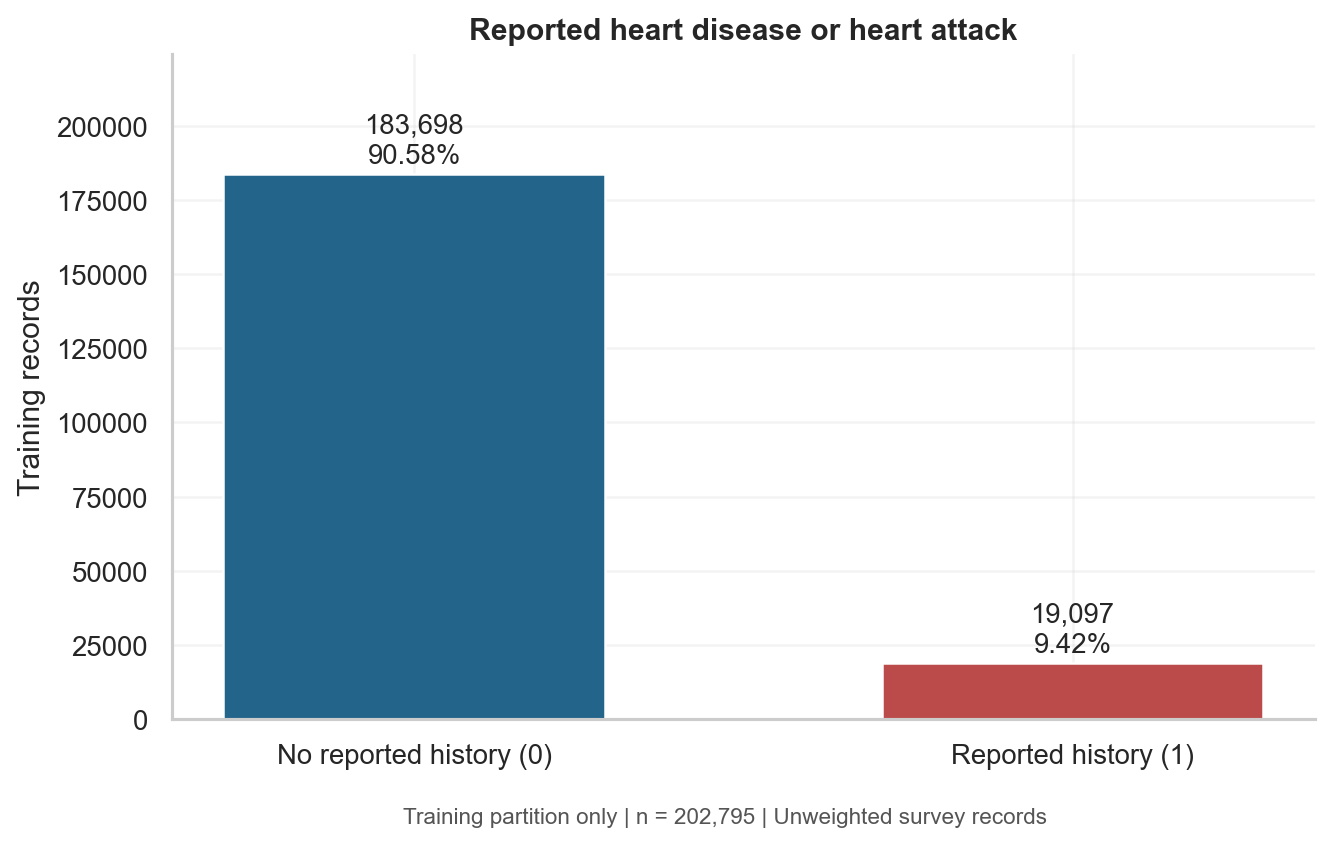

Always-negative training reference accuracy: 0.9058
Always-negative positive recall = 0; F1 = 0
Constant-score AP reference: 0.0942; ROC-AUC = 0.5


In [7]:
display(table('training_class_distribution.csv'))
figure('01_class_distribution.png', 760)
print(f"Always-negative training reference accuracy: {facts['training_majority_baseline_accuracy']:.4f}")
print('Always-negative positive recall = 0; F1 = 0')
print(f"Constant-score AP reference: {facts['training_constant_score_average_precision']:.4f}; ROC-AUC = 0.5")

### Age bands and reported disease

Compare the positive percentage **within** each age band, rather than raw case counts. Larger groups can otherwise dominate a count chart. This descriptive relationship does not identify the effect of ageing independently of other variables.

,Age,age_band,count,positives,rate
0,1,18-24,4559,22,0.0048
1,2,25-29,6133,43,0.0070
2,3,30-34,8896,99,0.0111
3,4,35-39,11147,159,0.0143
4,5,40-44,12850,281,0.0219
5,6,45-49,15743,571,0.0363
6,7,50-54,20990,1144,0.0545
7,8,55-59,24774,1802,0.0727
8,9,60-64,26479,2664,0.1006
9,10,65-69,25817,3392,0.1314


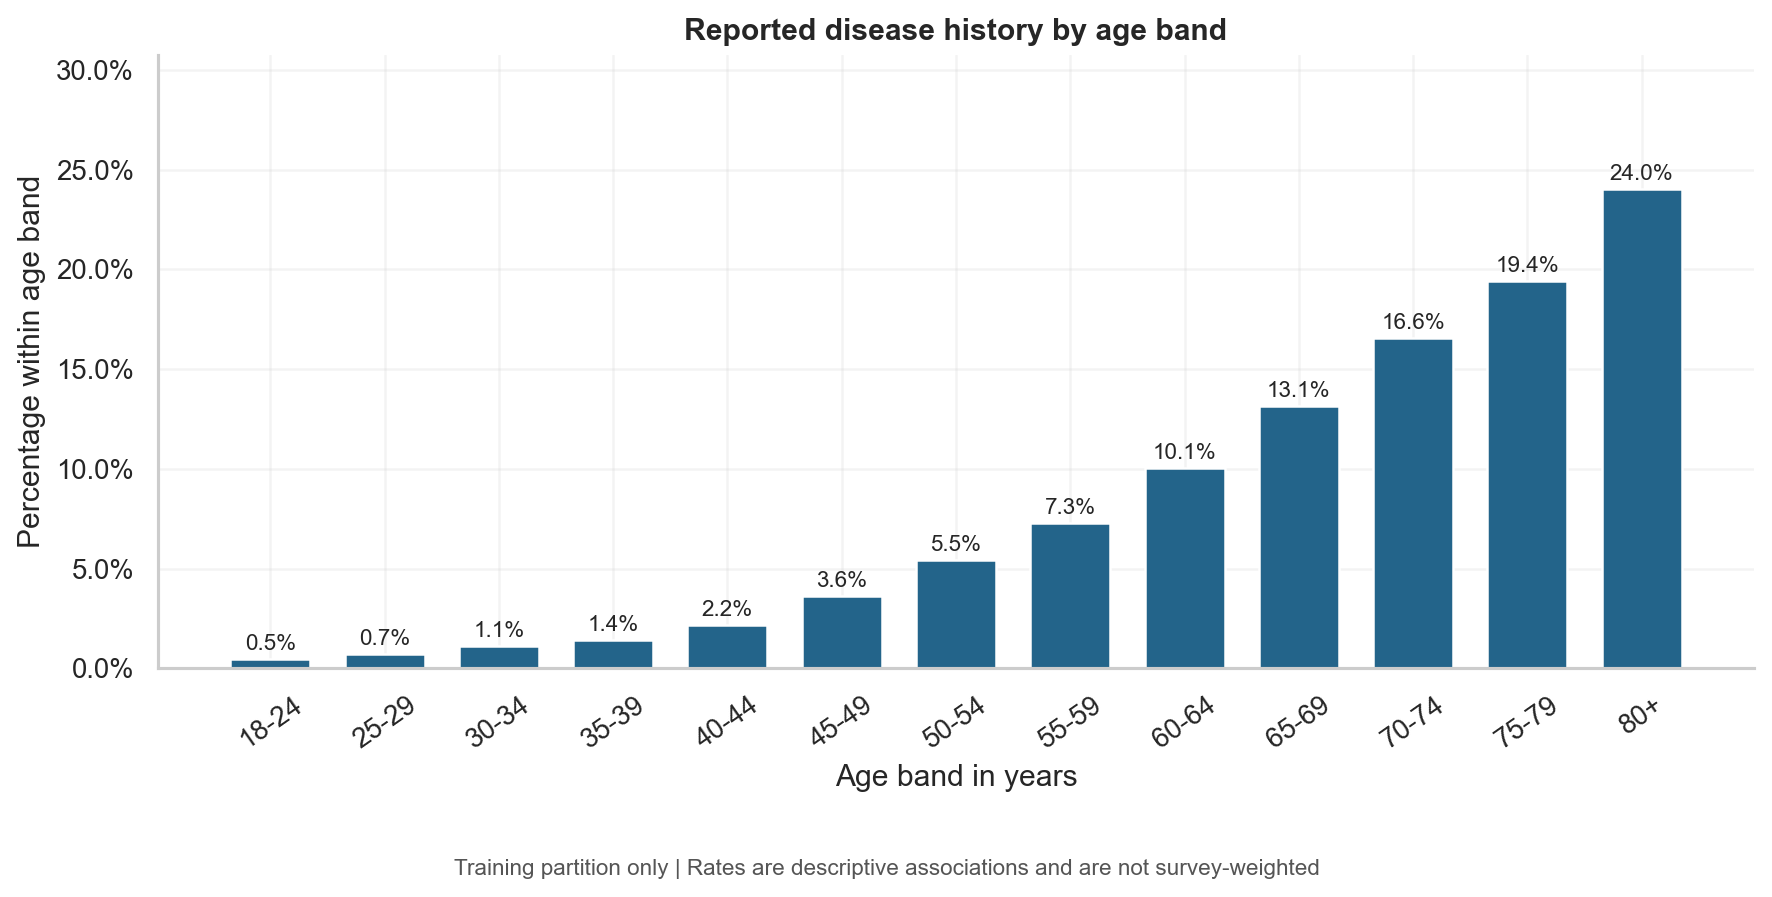

In [8]:
display(table('age_target_rates.csv').round(4))
figure('02_age_disease_rate.png')

### BMI distribution and extreme values

Review the full distribution and both target classes. The 1.5-IQR rule identifies statistical extremes; it does not establish that a value is an error. No valid BMI values are removed or clipped. Poor-health days are bounded counts from 0 to 30, and their valid zeros are retained.

,0
q1,24.0
q3,31.0
iqr,7.0
lower_fence,13.5
upper_fence,41.5
flagged_rows,7870
flagged_percent,3.880766
minimum,12
maximum,98
removed_rows,0


BMI        MentHlth        PhysHlth       
                       mean median     mean median     mean median
HeartDiseaseorAttack                                              
0                     28.27   27.0     3.02    0.0     3.73    0.0
1                     29.45   28.0     4.69    0.0     9.15    2.0

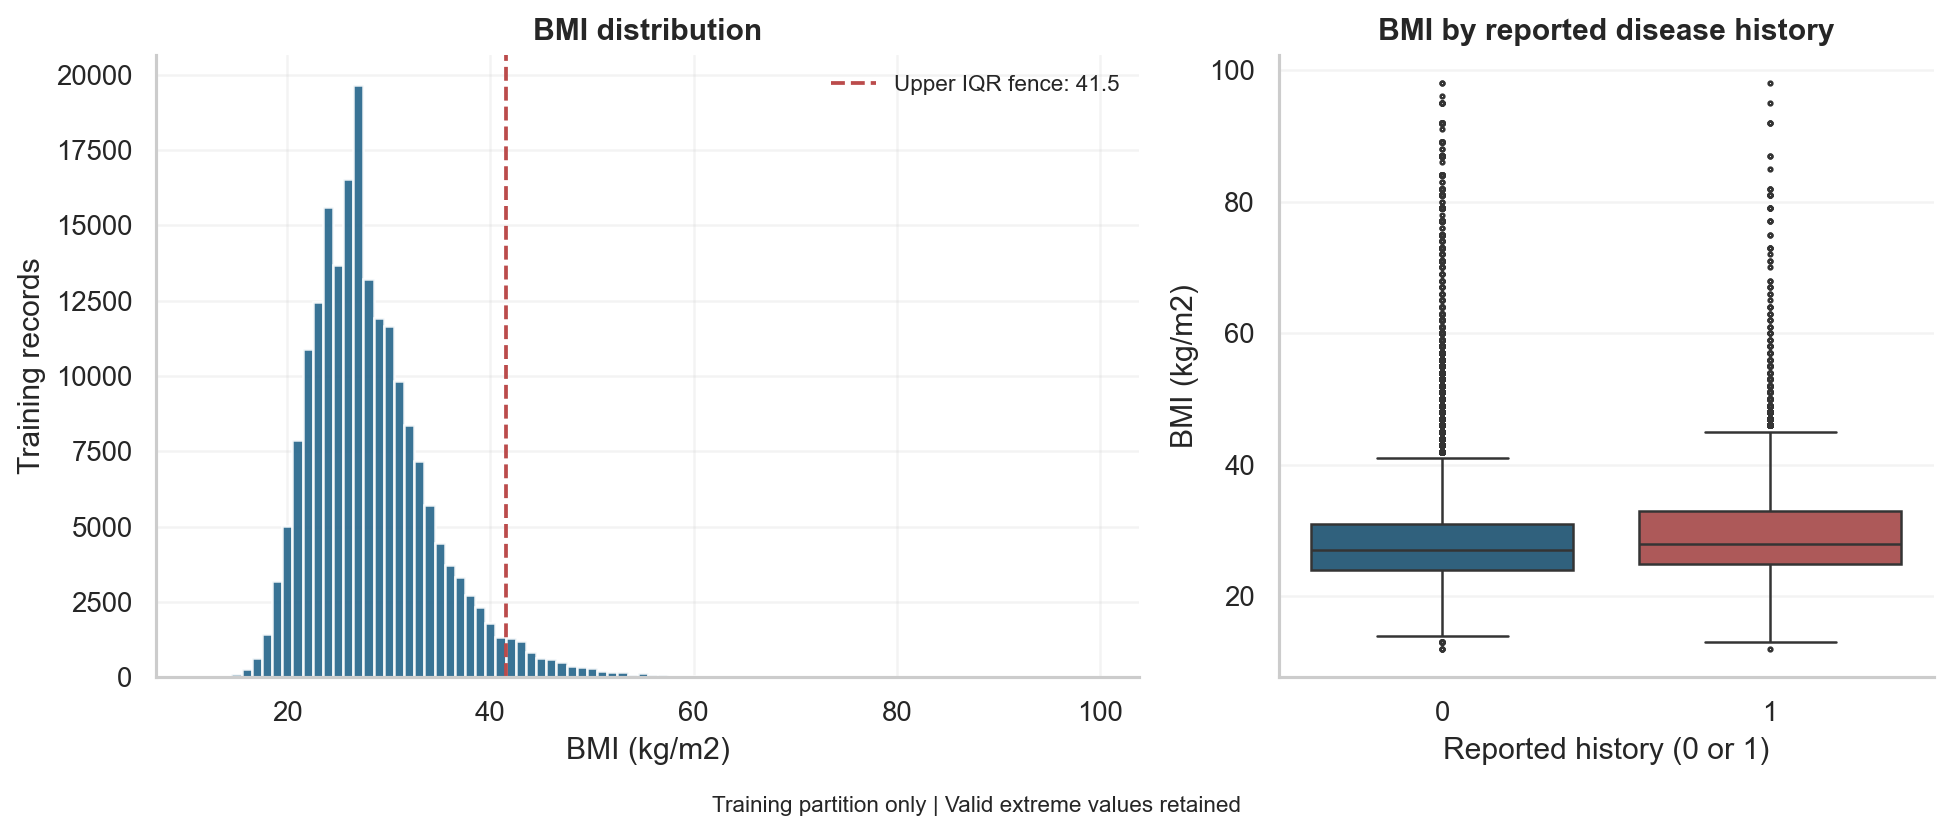

In [9]:
display(table('bmi_outlier_audit.csv').T)
display(train.groupby(TARGET)[['BMI', 'MentHlth', 'PhysHlth']].agg(['mean', 'median']).round(2))
figure('03_bmi_distribution.png')

### Correlations and target associations

Spearman correlations summarize rank relationships between numeric survey codes. Coding and category order affect their meaning. They cannot establish causation, clinical importance, or a feature's contribution to a fitted multivariable model. All 21 inputs are retained at this stage.

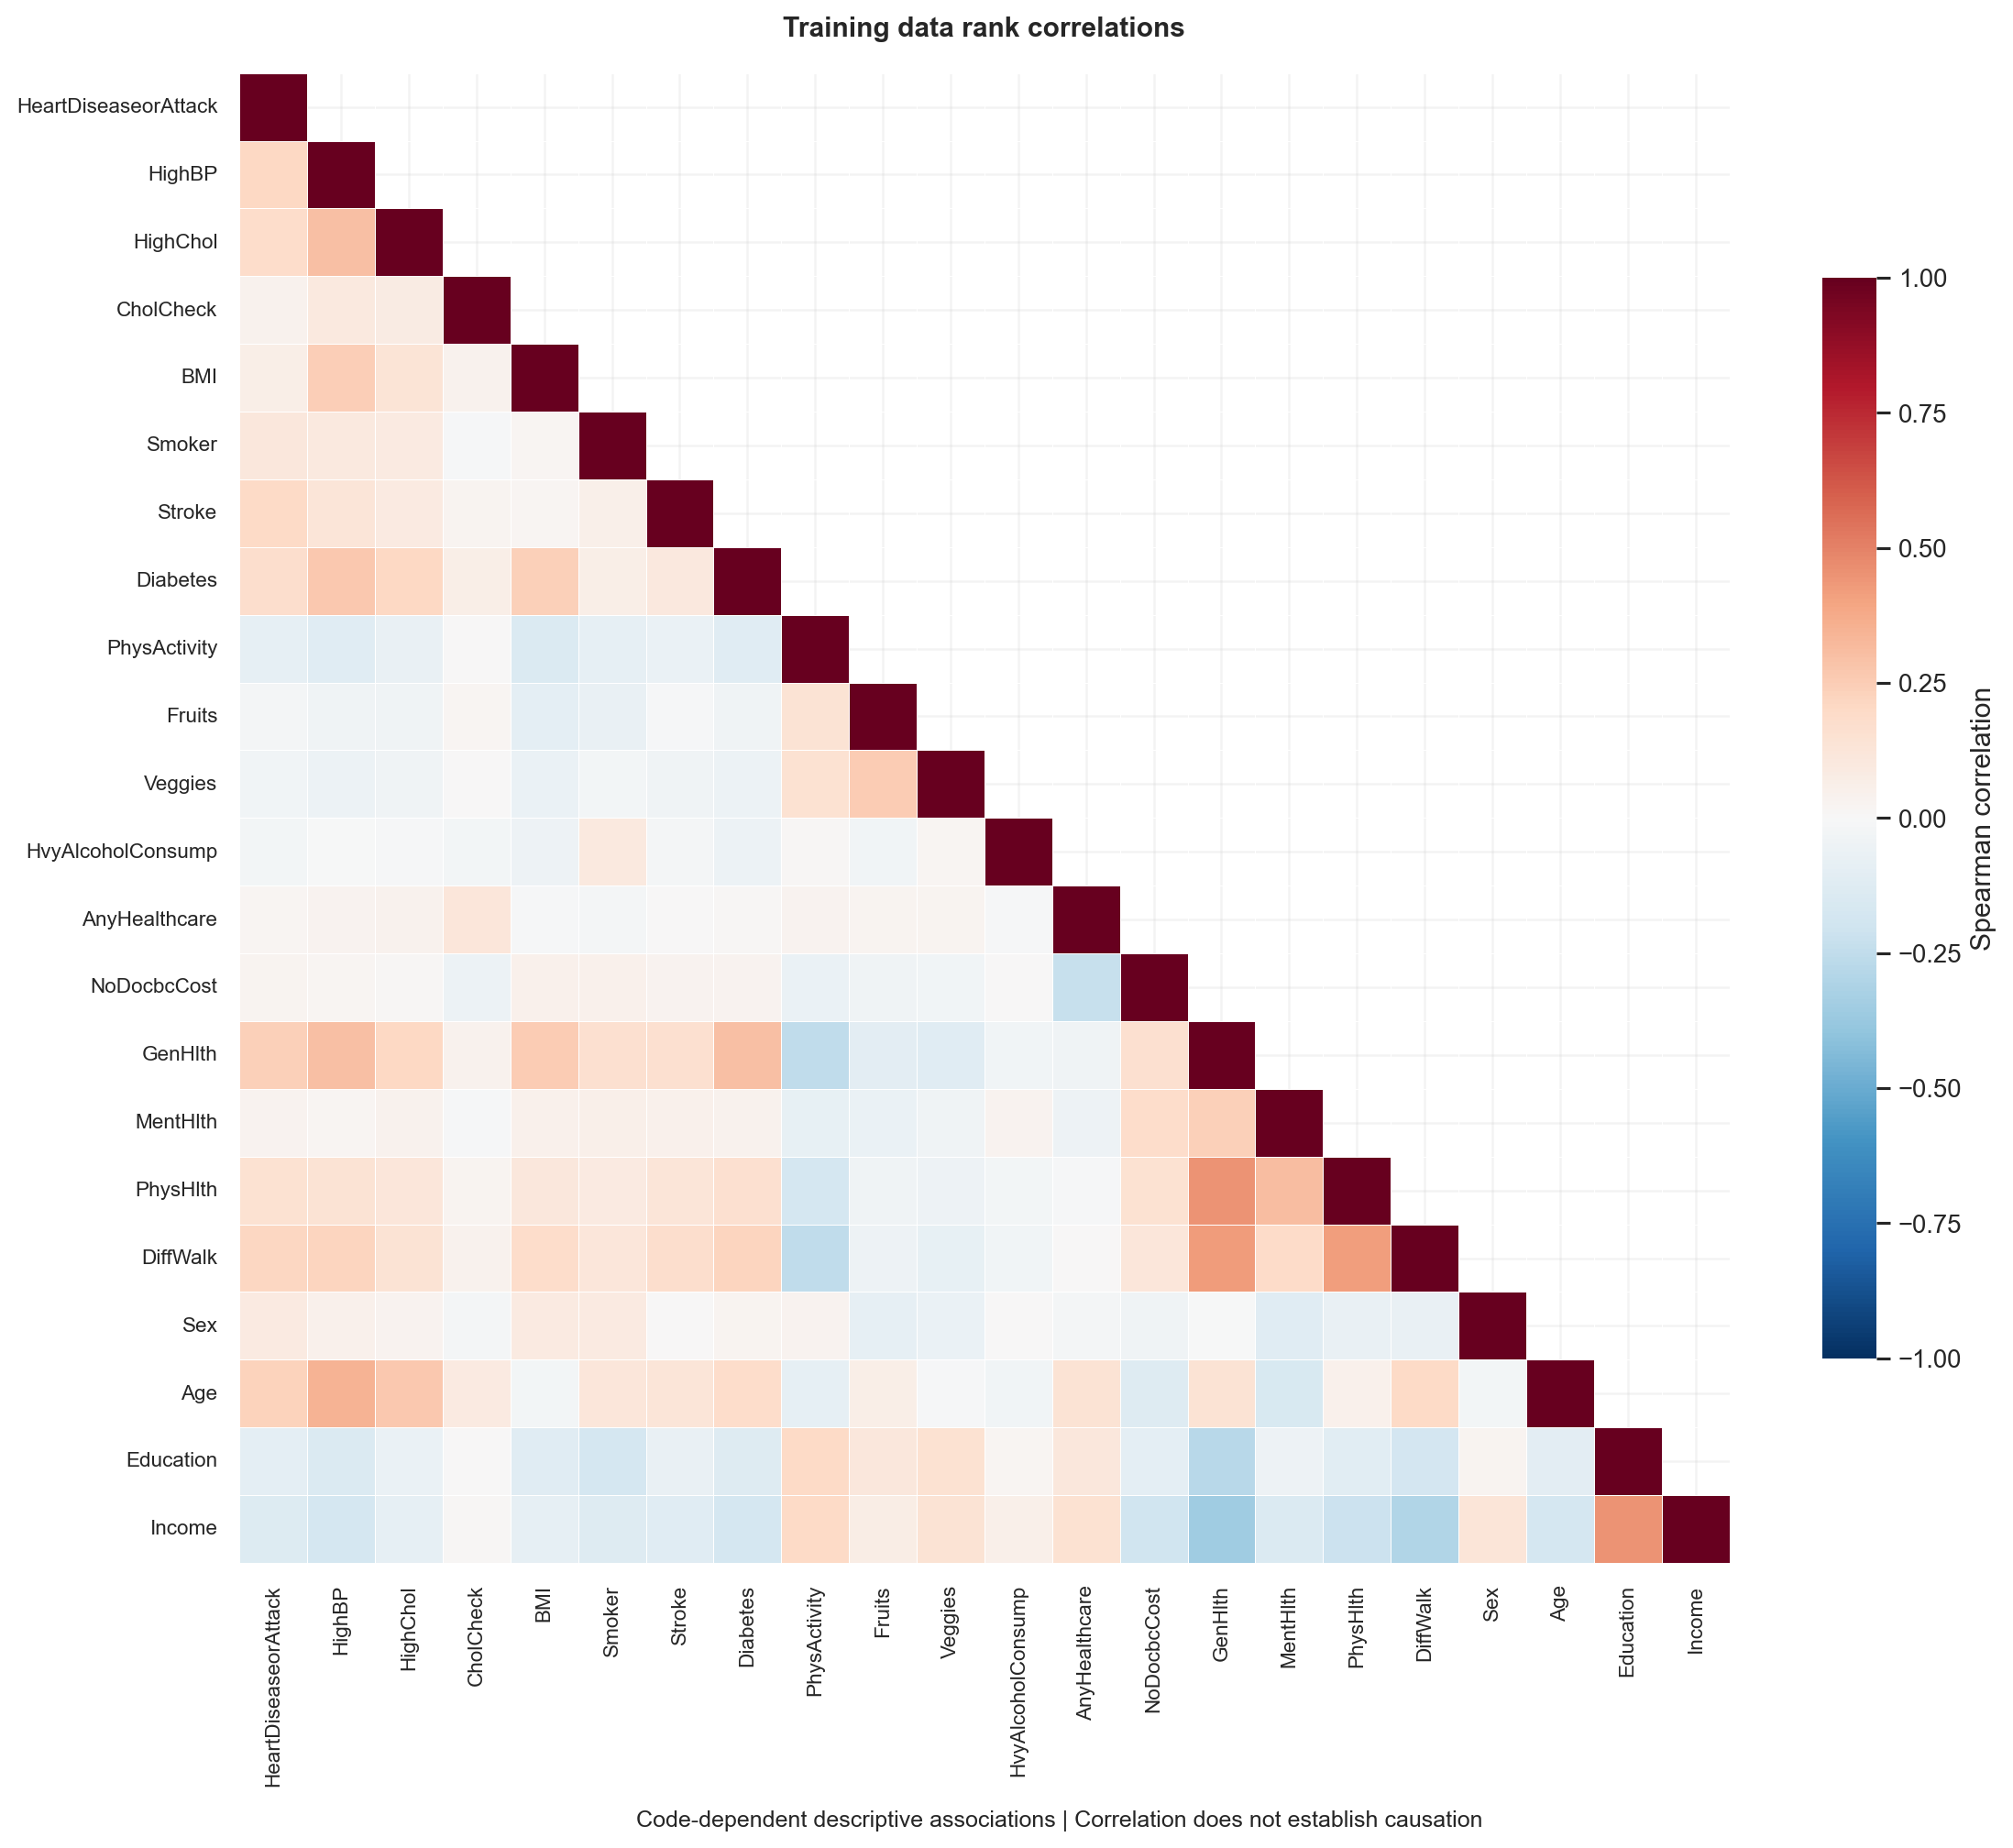

,feature,spearman_r
0,GenHlth,0.2404
1,Age,0.2275
2,DiffWalk,0.2119
3,HighBP,0.2076
4,Stroke,0.2023
5,HighChol,0.1804
6,Diabetes,0.1743
7,PhysHlth,0.1559
8,Income,-0.1401
9,Smoker,0.1160


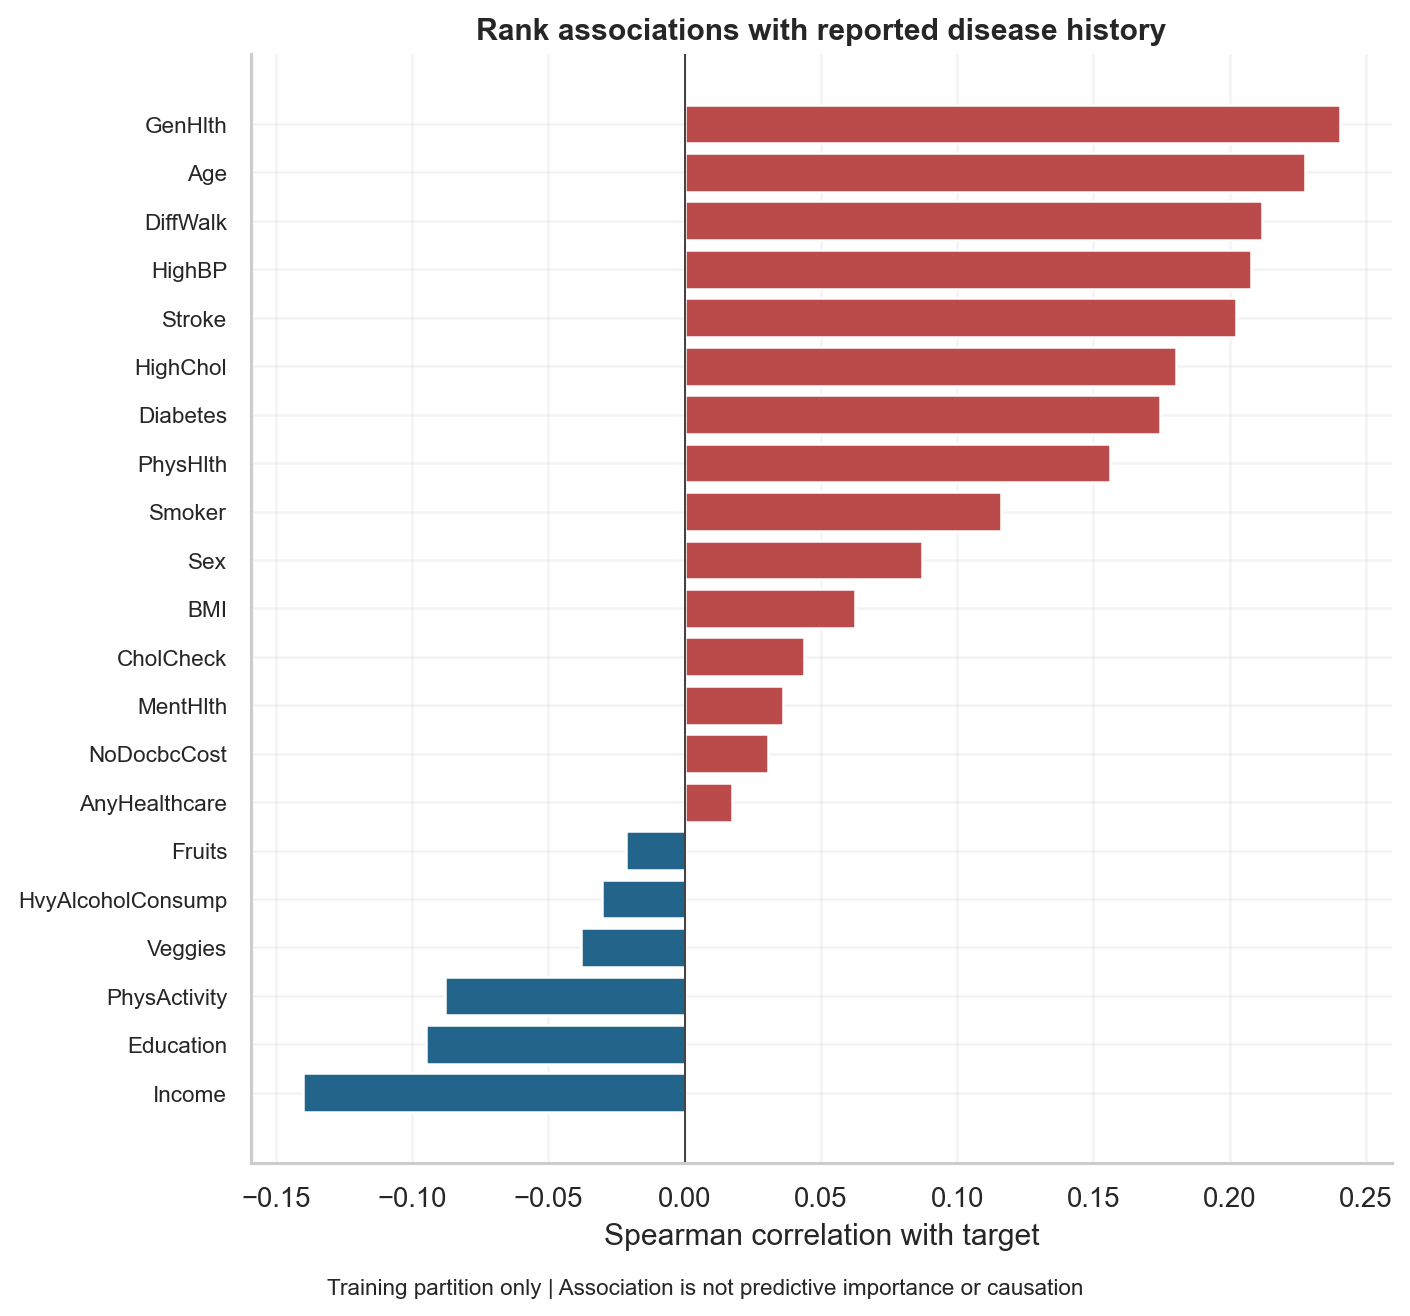

In [10]:
figure('04_spearman_heatmap.png', 1000)
display(table('target_rank_associations.csv').round(4))
figure('06_target_associations.png', 760)

### Smoking blood pressure and general health

`Smoker=1` means at least 100 lifetime cigarettes; it is not a current-smoking diagnosis. The following comparisons are marginal associations. General health and physical functioning may have been affected by earlier disease, so they should not be presented as proof of prospective risk prediction.

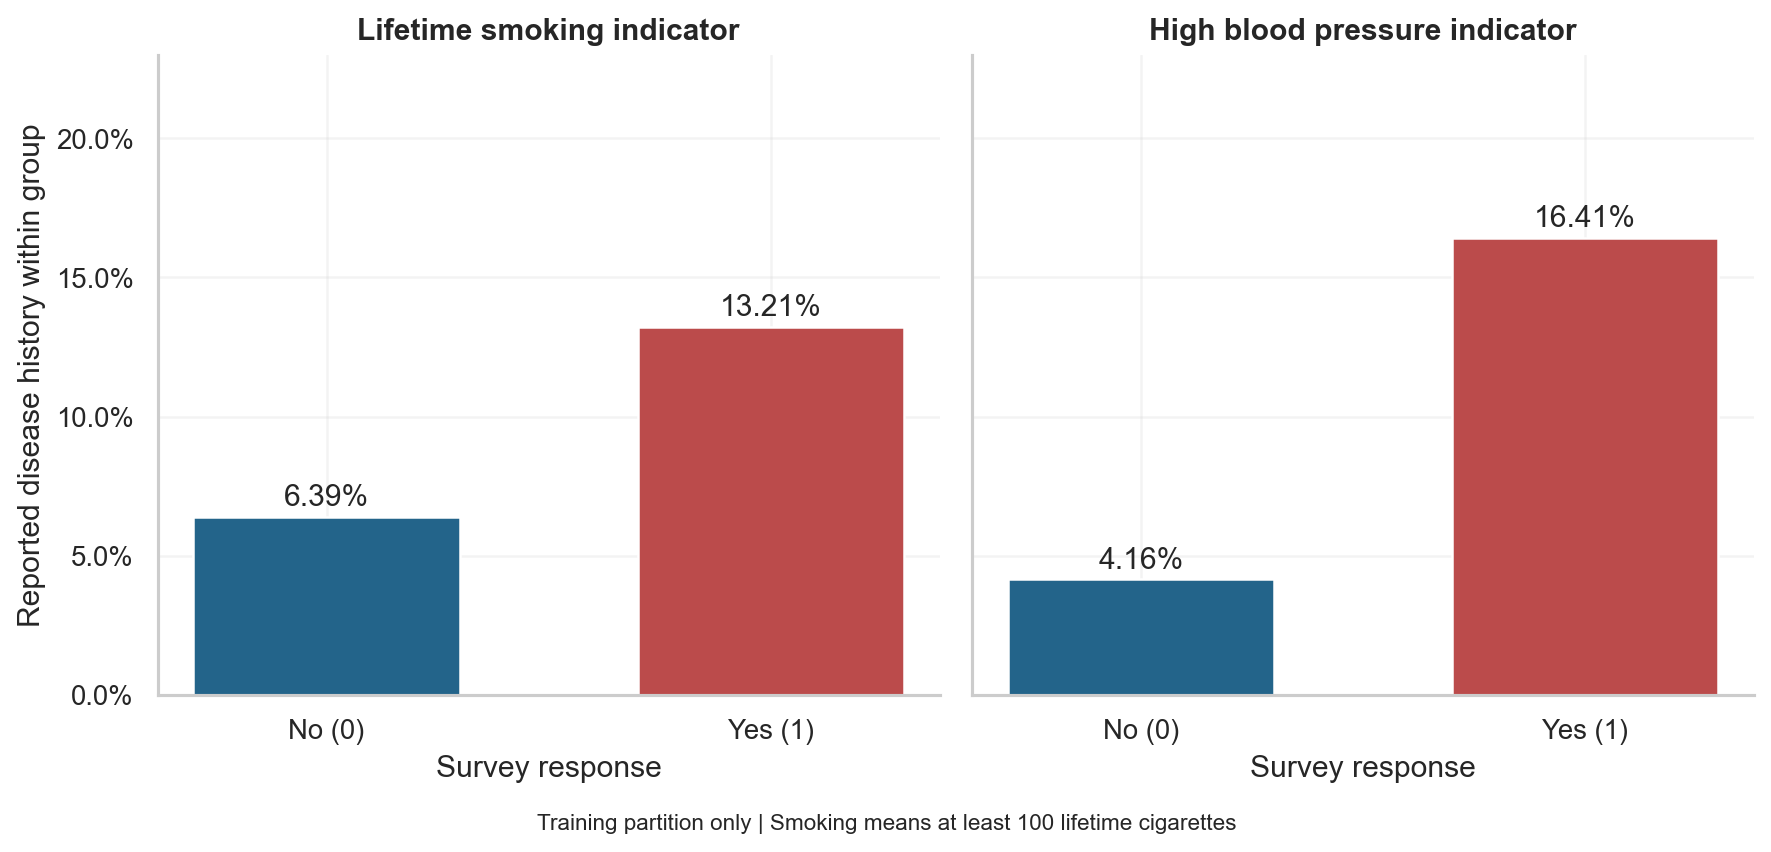

,Smoker,HighBP,count,positives,rate
0,0,0,69255,1855,0.0268
1,0,1,43584,5358,0.1229
2,1,0,46499,2958,0.0636
3,1,1,43457,8926,0.2054


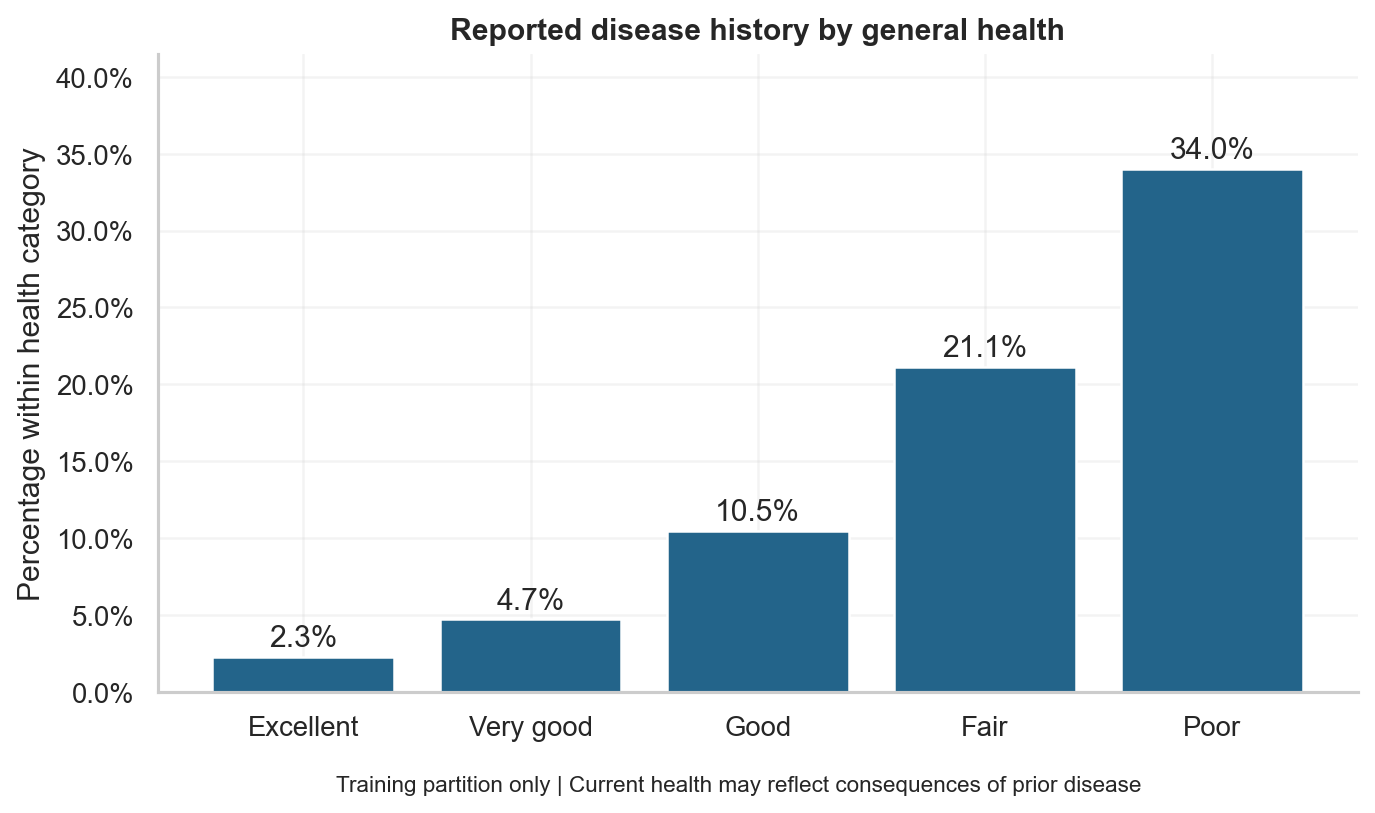

In [11]:
figure('05_smoking_and_blood_pressure.png')
display(table('smoking_blood_pressure_joint_rates.csv').round(4))
figure('07_general_health.png', 800)

## Part C Preprocessing pipelines

The processed CSVs hold **unscaled, original survey codes**. Transformations are packaged with each estimator so that every CV fit learns them from its own fitting rows.

| Step | Logistic regression | Decision tree and random forest | Reason |
| --- | --- | --- | --- |
| Missing values | Median for numeric; mode for categories | Same | Defensive pipeline; none missing in this CSV |
| BMI and health days | StandardScaler | Keep original scale | Linear optimization benefits from comparable scales |
| Age, health, education, income | One-hot categories | Ordered survey codes | Avoid equal-step linear effects; trees can split ordered codes |
| Diabetes | One-hot categories | One-hot categories | Preserve the three distinct statuses |
| Binary inputs | Original 0/1 codes | Original 0/1 codes | Already encoded |
| Imbalance | Compare class weights inside CV | Compare class weights inside CV | Preserve natural evaluation prevalence |
| Extreme valid values | Retain | Retain | No verified recording errors |

No model has been fitted and no globally scaled dataset is exported. Do not resample before splitting. If sampling is later investigated, it must be inside the CV pipeline and respect categorical variables.

In [12]:
X_train, y_train, metadata = load_training_bundle(ROOT)
assert TARGET not in X_train
assert list(X_train.columns) == FEATURES
assert len(X_train) == len(y_train) == len(metadata)
checks = verify_preprocessor_on_training(X_train, metadata)
display(pd.DataFrame(checks).T)
display(table('validation_fold_summary.csv').round(4))
print('All preprocessing checks passed using development data only.')

,fitted_on_rows,validated_on_rows,output_columns,finite
linear,162469,40326,46,True
tree,162469,40326,23,True


,fold,rows,positive,positive_rate
0,0,40326,3830,0.0950
1,1,40698,3789,0.0931
2,2,40558,3837,0.0946
3,3,40750,3838,0.0942
4,4,40463,3803,0.0940


All preprocessing checks passed using development data only.


---
# Section 2. Part D: Logistic Regression Baseline (Member 2)

*Source notebook: `notebooks/02_member2_logistic_regression.ipynb`*

In [13]:
from pathlib import Path
import sys

# Set project directory
# Locate the project folder from wherever the notebook is opened
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "model_setup.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Allow importing project modules
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Import shared data preparation
from src.data_preparation import load_training_bundle

# Load training data
X_train, y_train, metadata = load_training_bundle(ROOT)

# Display dataset information
print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)
print("Metadata:", metadata.shape)

print("\nTarget Distribution:")
print(y_train.value_counts())

Training Features: (202795, 21)
Training Target: (202795,)
Metadata: (202795, 4)

Target Distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [14]:
from sklearn.linear_model import LogisticRegression
from src.model_setup import make_model_pipeline, shared_cv

# Create Logistic Regression baseline model
lr_model = make_model_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    kind="linear"
)

# Use shared 5-fold cross-validation
cv = shared_cv(metadata)

print("Logistic Regression Baseline Model Created")
print("\nModel Pipeline:")
print(lr_model)

print("\nNumber of CV Splits:", cv.get_n_splits())

Logistic Regression Baseline Model Created

Model Pipeline:
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke', 'PhysActi

In [15]:
import pandas as pd
from sklearn.model_selection import cross_validate

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

# Train and evaluate using shared 5-fold CV
lr_cv_results = cross_validate(
    estimator=lr_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Summarise validation results
lr_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Validation Score": [
        lr_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        lr_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Logistic Regression Baseline - 5-Fold Cross-Validation")
display(lr_summary.round(4))

Logistic Regression Baseline - 5-Fold Cross-Validation


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.9074,0.0012
1,Precision,0.5353,0.0192
2,Recall,0.1234,0.0049
3,F1,0.2005,0.0076
4,ROC_AUC,0.8465,0.0038
5,Average_Precision,0.3687,0.0065


In [16]:
from pathlib import Path

# Create results folder
results_dir = ROOT / "results" / "member2"
results_dir.mkdir(parents=True, exist_ok=True)

# Save Logistic Regression baseline results
lr_summary.to_csv(
    results_dir / "logistic_regression_baseline.csv",
    index=False
)

print("Logistic Regression Baseline Results Saved Successfully")

Logistic Regression Baseline Results Saved Successfully


In [17]:
# Compare training and validation performance
overfitting_results = pd.DataFrame({
    "Metric": ["Accuracy", "F1", "ROC_AUC", "Average_Precision"],
    "Training Score": [
        lr_cv_results[f"train_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ],
    "Validation Score": [
        lr_cv_results[f"test_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ]
})

overfitting_results["Gap"] = (
    overfitting_results["Training Score"]
    - overfitting_results["Validation Score"]
)

display(overfitting_results.round(4))

,Metric,Training Score,Validation Score,Gap
0,Accuracy,0.9074,0.9074,0.0001
1,F1,0.2011,0.2005,0.0006
2,ROC_AUC,0.8470,0.8465,0.0005
3,Average_Precision,0.3693,0.3687,0.0007


In [18]:
# Save overfitting results
overfitting_results.to_csv(
    results_dir / "logistic_regression_overfitting.csv",
    index=False
)

print("Logistic Regression Overfitting Results Saved Successfully")

Logistic Regression Overfitting Results Saved Successfully


---
# Section 3. Part D: Decision Tree Baseline (Member 2)

*Source notebook: `notebooks/03_member2_decision_tree.ipynb`*

In [19]:
from pathlib import Path
import sys
import pandas as pd

# Set project root
# Locate the project folder from wherever the notebook is opened
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "model_setup.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Enable imports from the project
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Import training setup
from src.data_preparation import load_training_bundle
from src.model_setup import make_model_pipeline, shared_cv

# Load shared training dataset
X_train, y_train, metadata = load_training_bundle(ROOT)

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)
print("Metadata:", metadata.shape)

print("\nTarget Distribution:")
print(y_train.value_counts())

Training Features: (202795, 21)
Training Target: (202795,)
Metadata: (202795, 4)

Target Distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [20]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree baseline model
dt_model = make_model_pipeline(
    DecisionTreeClassifier(
        random_state=42
    ),
    kind="tree"
)

# Use shared 5-fold cross-validation
cv = shared_cv(metadata)

print("Decision Tree Baseline Model Created")

print("\nModel Configuration:")
print(dt_model.named_steps["model"])

print("\nNumber of CV Splits:", cv.get_n_splits())

Decision Tree Baseline Model Created

Model Configuration:
DecisionTreeClassifier(random_state=42)

Number of CV Splits: 5


In [21]:
import pandas as pd
from sklearn.model_selection import cross_validate

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

# Train and evaluate using shared 5-fold CV
dt_cv_results = cross_validate(
    estimator=dt_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Summarise validation results
dt_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Validation Score": [
        dt_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        dt_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Decision Tree Baseline - 5-Fold Cross-Validation")
display(dt_summary.round(4))

Decision Tree Baseline - 5-Fold Cross-Validation


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.8521,0.0007
1,Precision,0.2459,0.0032
2,Recall,0.2758,0.0059
3,F1,0.2600,0.0044
4,ROC_AUC,0.5962,0.0030
5,Average_Precision,0.1379,0.0022


In [22]:
# Compare training and validation performance
dt_overfitting = pd.DataFrame({
    "Metric": ["Accuracy", "F1", "ROC_AUC", "Average_Precision"],
    "Training Score": [
        dt_cv_results[f"train_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ],
    "Validation Score": [
        dt_cv_results[f"test_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ]
})

dt_overfitting["Gap"] = (
    dt_overfitting["Training Score"]
    - dt_overfitting["Validation Score"]
)

print("Decision Tree Training vs Validation Performance")
display(dt_overfitting.round(4))

Decision Tree Training vs Validation Performance


,Metric,Training Score,Validation Score,Gap
0,Accuracy,0.9953,0.8521,0.1432
1,F1,0.9746,0.2600,0.7146
2,ROC_AUC,0.9998,0.5962,0.4037
3,Average_Precision,0.9981,0.1379,0.8601


In [23]:
# Fit Decision Tree on the complete training dataset
dt_model.fit(X_train, y_train)

# Access the trained Decision Tree inside the pipeline
trained_tree = dt_model.named_steps["model"]

# Examine model complexity
print("Decision Tree Model Complexity")
print("Tree Depth:", trained_tree.get_depth())
print("Number of Leaf Nodes:", trained_tree.get_n_leaves())
print("Number of Nodes:", trained_tree.tree_.node_count)

Decision Tree Model Complexity
Tree Depth: 43
Number of Leaf Nodes: 27795
Number of Nodes: 55589


In [24]:
import pandas as pd

# Get feature names after preprocessing
feature_names = dt_model.named_steps["preprocess"].get_feature_names_out()

# Get feature importance from trained Decision Tree
importance_values = trained_tree.feature_importances_

# Create feature importance dataframe
dt_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features from highest to lowest importance
dt_feature_importance = dt_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Decision Tree - Top 10 Important Features")
display(dt_feature_importance.head(10).round(4))

Decision Tree - Top 10 Important Features


,Feature,Importance
0,numeric__BMI,0.1898
19,ordinal__Income,0.1121
17,ordinal__Age,0.0891
2,numeric__PhysHlth,0.0886
16,ordinal__GenHlth,0.0809
18,ordinal__Education,0.0763
1,numeric__MentHlth,0.0658
9,binary__Fruits,0.0366
8,binary__PhysActivity,0.0328
10,binary__Veggies,0.0289


In [25]:
from pathlib import Path
import pandas as pd

# Create results folder
results_dir = ROOT / "results" / "member2"
results_dir.mkdir(parents=True, exist_ok=True)

# Save baseline performance results
dt_summary.to_csv(
    results_dir / "decision_tree_baseline.csv",
    index=False
)

# Save training and validation comparison
dt_overfitting.to_csv(
    results_dir / "decision_tree_overfitting.csv",
    index=False
)

# Save feature importance
dt_feature_importance.to_csv(
    results_dir / "decision_tree_feature_importance.csv",
    index=False
)

# Save tree complexity
dt_complexity = pd.DataFrame([{
    "Tree Depth": trained_tree.get_depth(),
    "Leaf Nodes": trained_tree.get_n_leaves(),
    "Total Nodes": trained_tree.tree_.node_count
}])

dt_complexity.to_csv(
    results_dir / "decision_tree_complexity.csv",
    index=False
)

print("All Decision Tree Baseline Results Saved Successfully")

All Decision Tree Baseline Results Saved Successfully


---
# Section 4. Part E: Logistic Regression Optimisation (Member 2)

*Source notebook: `notebooks/04_member2_logistic_optimisation.ipynb`*

In [26]:
from pathlib import Path
import sys

# Locate the project folder from wherever the notebook is opened
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "model_setup.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_preparation import load_training_bundle
from src.model_setup import make_model_pipeline, shared_cv

X_train, y_train, metadata = load_training_bundle(ROOT)
cv = shared_cv(metadata)

print("Training Records:", X_train.shape[0])
print("Number of Features:", X_train.shape[1])
print("CV Folds:", cv.get_n_splits())

print("\nTarget Distribution:")
print(y_train.value_counts())

Training Records: 202795
Number of Features: 21
CV Folds: 5

Target Distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

# Create Logistic Regression model
lr_model = make_model_pipeline(
    LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    kind="linear"
)

# Define hyperparameter search space
lr_param_distributions = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
    "model__solver": ["lbfgs", "liblinear"]
}

print("Logistic Regression Optimisation Model Created")
print("\nHyperparameter Search Space:")

for parameter, values in lr_param_distributions.items():
    print(f"{parameter}: {values}")

print("\nCross-Validation Folds:", cv.get_n_splits())
print("Primary Evaluation Metric: Average Precision")

Logistic Regression Optimisation Model Created

Hyperparameter Search Space:
model__C: [0.001, 0.01, 0.1, 1, 10, 100]
model__class_weight: [None, 'balanced']
model__solver: ['lbfgs', 'liblinear']

Cross-Validation Folds: 5
Primary Evaluation Metric: Average Precision


In [28]:
# Configure RandomizedSearchCV
lr_search = RandomizedSearchCV(
    estimator=lr_model,
    param_distributions=lr_param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=True
)

# Run hyperparameter optimisation
lr_search.fit(X_train, y_train)

# Display best results
print("\nLogistic Regression Optimisation Completed")
print("\nBest Hyperparameters:")

for parameter, value in lr_search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest Cross-Validation Average Precision: {lr_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits



Logistic Regression Optimisation Completed

Best Hyperparameters:
model__solver: lbfgs
model__class_weight: None
model__C: 0.1

Best Cross-Validation Average Precision: 0.3689


In [29]:
import pandas as pd
from sklearn.model_selection import cross_validate

# Get the best Logistic Regression model
lr_optimised_model = lr_search.best_estimator_

# Evaluate using the same 5-fold cross-validation
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

lr_optimised_cv = cross_validate(
    estimator=lr_optimised_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Summarise validation performance
lr_optimised_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean": [
        lr_optimised_cv[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Std": [
        lr_optimised_cv[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Optimised Logistic Regression - 5-Fold CV Results")
display(lr_optimised_summary.round(4))

Optimised Logistic Regression - 5-Fold CV Results


,Metric,Mean,Std
0,Accuracy,0.9074,0.0012
1,Precision,0.5375,0.0186
2,Recall,0.1222,0.0056
3,F1,0.1991,0.0086
4,ROC_AUC,0.8465,0.0039
5,Average_Precision,0.3689,0.0066


In [30]:
import pandas as pd

# Load baseline results
baseline_path = (
    ROOT / "results" / "member2" /
    "logistic_regression_baseline.csv"
)
lr_baseline = pd.read_csv(baseline_path)

# Prepare baseline and optimised results
baseline = lr_baseline.set_index("Metric")
optimised = lr_optimised_summary.set_index("Metric")

# Compare mean and standard deviation
lr_comparison = pd.DataFrame({
    "Metric": optimised.index,
    "Baseline Mean": baseline["Mean Validation Score"].reindex(optimised.index).values,
    "Baseline Std": baseline["Standard Deviation"].reindex(optimised.index).values,
    "Optimised Mean": optimised["Mean"].values,
    "Optimised Std": optimised["Std"].values
})

# Calculate performance difference
lr_comparison["Mean Change"] = (
    lr_comparison["Optimised Mean"] - lr_comparison["Baseline Mean"]
)

print("Logistic Regression - Baseline vs Optimised")
display(lr_comparison.round(4))

Logistic Regression - Baseline vs Optimised


,Metric,Baseline Mean,Baseline Std,Optimised Mean,Optimised Std,Mean Change
0,Accuracy,0.9074,0.0012,0.9074,0.0012,0.0001
1,Precision,0.5353,0.0192,0.5375,0.0186,0.0022
2,Recall,0.1234,0.0049,0.1222,0.0056,-0.0012
3,F1,0.2005,0.0076,0.1991,0.0086,-0.0014
4,ROC_AUC,0.8465,0.0038,0.8465,0.0039,-0.0000
5,Average_Precision,0.3687,0.0065,0.3689,0.0066,0.0002


In [31]:
# Compare optimised training and validation performance
lr_optimised_overfitting = pd.DataFrame({
    "Metric": ["Accuracy", "F1", "ROC_AUC", "Average_Precision"],
    "Training Score": [
        lr_optimised_cv[f"train_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ],
    "Validation Score": [
        lr_optimised_cv[f"test_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ]
})

# Calculate the performance gap
lr_optimised_overfitting["Gap"] = (
    lr_optimised_overfitting["Training Score"]
    - lr_optimised_overfitting["Validation Score"]
)

print("Optimised Logistic Regression - Training vs Validation")
display(lr_optimised_overfitting.round(4))

Optimised Logistic Regression - Training vs Validation


,Metric,Training Score,Validation Score,Gap
0,Accuracy,0.9075,0.9074,0.0001
1,F1,0.2002,0.1991,0.0011
2,ROC_AUC,0.8470,0.8465,0.0005
3,Average_Precision,0.3694,0.3689,0.0005


In [32]:
import pandas as pd

# Use the existing results folder
results_dir = ROOT / "results" / "member2"
results_dir.mkdir(parents=True, exist_ok=True)

# Save optimised evaluation results
lr_optimised_summary.to_csv(
    results_dir / "logistic_regression_optimised.csv",
    index=False
)

# Save baseline vs optimised comparison
lr_comparison.to_csv(
    results_dir / "logistic_regression_optimisation_comparison.csv",
    index=False
)

# Save training vs validation analysis
lr_optimised_overfitting.to_csv(
    results_dir / "logistic_regression_optimised_overfitting.csv",
    index=False
)

# Save best hyperparameters
lr_best_params = pd.DataFrame(
    list(lr_search.best_params_.items()),
    columns=["Hyperparameter", "Best Value"]
)

lr_best_params.to_csv(
    results_dir / "logistic_regression_best_parameters.csv",
    index=False
)

print("All Logistic Regression Optimisation Results Saved Successfully")

All Logistic Regression Optimisation Results Saved Successfully


---
# Section 5. Part E: Decision Tree Optimisation (Member 2)

*Source notebook: `notebooks/05_member2_decision_tree_optimisation.ipynb`*

In [33]:
from pathlib import Path
import sys

# Locate the project folder from wherever the notebook is opened
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "model_setup.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_preparation import load_training_bundle
from src.model_setup import make_model_pipeline, shared_cv

# Load shared training dataset
X_train, y_train, metadata = load_training_bundle(ROOT)

# Use the same predefined 5-fold cross-validation
cv = shared_cv(metadata)

print("Training Records:", X_train.shape[0])
print("Number of Features:", X_train.shape[1])
print("CV Folds:", cv.get_n_splits())

print("\nTarget Distribution:")
print(y_train.value_counts())

Training Records: 202795
Number of Features: 21
CV Folds: 5

Target Distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV

# Create Decision Tree model
dt_model = make_model_pipeline(
    DecisionTreeClassifier(random_state=42),
    kind="tree"
)

# Define hyperparameter search space
dt_param_distributions = {
    "model__max_depth": [5, 10, 15, 20, 30],
    "model__min_samples_split": [2, 10, 20, 50],
    "model__min_samples_leaf": [1, 10, 30, 50],
    "model__class_weight": [None, "balanced"]
}

print("Decision Tree Optimisation Model Created")
print("\nHyperparameter Search Space:")

for parameter, values in dt_param_distributions.items():
    print(f"{parameter}: {values}")

print("\nTotal Possible Combinations: 160")
print("Cross-Validation Folds:", cv.get_n_splits())
print("Primary Evaluation Metric: Average Precision")

Decision Tree Optimisation Model Created

Hyperparameter Search Space:
model__max_depth: [5, 10, 15, 20, 30]
model__min_samples_split: [2, 10, 20, 50]
model__min_samples_leaf: [1, 10, 30, 50]
model__class_weight: [None, 'balanced']

Total Possible Combinations: 160
Cross-Validation Folds: 5
Primary Evaluation Metric: Average Precision


In [35]:
# Configure RandomizedSearchCV
dt_search = RandomizedSearchCV(
    estimator=dt_model,
    param_distributions=dt_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=True
)

# Run hyperparameter optimisation
dt_search.fit(X_train, y_train)

# Display best results
print("\nDecision Tree Optimisation Completed")

print("\nBest Hyperparameters:")
for parameter, value in dt_search.best_params_.items():
    print(f"{parameter}: {value}")

print(
    f"\nBest Cross-Validation Average Precision: "
    f"{dt_search.best_score_:.4f}"
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits



Decision Tree Optimisation Completed

Best Hyperparameters:
model__min_samples_split: 10
model__min_samples_leaf: 50
model__max_depth: 10
model__class_weight: None

Best Cross-Validation Average Precision: 0.3407


In [36]:
import pandas as pd
from sklearn.model_selection import cross_validate

# Get the best Decision Tree model
dt_optimised_model = dt_search.best_estimator_

# Define evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

# Evaluate optimised Decision Tree using 5-fold CV
dt_optimised_cv = cross_validate(
    estimator=dt_optimised_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Summarise validation results
dt_optimised_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean": [
        dt_optimised_cv[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Std": [
        dt_optimised_cv[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Optimised Decision Tree - 5-Fold CV Results")
display(dt_optimised_summary.round(4))

Optimised Decision Tree - 5-Fold CV Results


,Metric,Mean,Std
0,Accuracy,0.9066,0.0007
1,Precision,0.5233,0.0097
2,Recall,0.0889,0.0081
3,F1,0.1518,0.0119
4,ROC_AUC,0.8340,0.0038
5,Average_Precision,0.3407,0.0060


In [37]:
import pandas as pd

# Load Decision Tree baseline results
baseline_path = (
    ROOT / "results" / "member2" /
    "decision_tree_baseline.csv"
)
dt_baseline = pd.read_csv(baseline_path)

# Prepare baseline and optimised results
baseline = dt_baseline.set_index("Metric")
optimised = dt_optimised_summary.set_index("Metric")

# Compare mean and standard deviation
dt_comparison = pd.DataFrame({
    "Metric": optimised.index,
    "Baseline Mean": baseline["Mean Validation Score"].reindex(optimised.index).values,
    "Baseline Std": baseline["Standard Deviation"].reindex(optimised.index).values,
    "Optimised Mean": optimised["Mean"].values,
    "Optimised Std": optimised["Std"].values
})

# Calculate mean performance change
dt_comparison["Mean Change"] = (
    dt_comparison["Optimised Mean"] - dt_comparison["Baseline Mean"]
)

print("Decision Tree - Baseline vs Optimised")
display(dt_comparison.round(4))

Decision Tree - Baseline vs Optimised


,Metric,Baseline Mean,Baseline Std,Optimised Mean,Optimised Std,Mean Change
0,Accuracy,0.8521,0.0007,0.9066,0.0007,0.0544
1,Precision,0.2459,0.0032,0.5233,0.0097,0.2774
2,Recall,0.2758,0.0059,0.0889,0.0081,-0.1869
3,F1,0.2600,0.0044,0.1518,0.0119,-0.1082
4,ROC_AUC,0.5962,0.0030,0.8340,0.0038,0.2378
5,Average_Precision,0.1379,0.0022,0.3407,0.0060,0.2028


In [38]:
# Compare optimised training and validation performance
dt_optimised_overfitting = pd.DataFrame({
    "Metric": ["Accuracy", "F1", "ROC_AUC", "Average_Precision"],
    "Training Score": [
        dt_optimised_cv[f"train_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ],
    "Validation Score": [
        dt_optimised_cv[f"test_{metric}"].mean()
        for metric in ["Accuracy", "F1", "ROC_AUC", "Average_Precision"]
    ]
})

# Calculate performance gaps
dt_optimised_overfitting["Gap"] = (
    dt_optimised_overfitting["Training Score"]
    - dt_optimised_overfitting["Validation Score"]
)

print("Optimised Decision Tree - Training vs Validation")
display(dt_optimised_overfitting.round(4))

Optimised Decision Tree - Training vs Validation


,Metric,Training Score,Validation Score,Gap
0,Accuracy,0.9091,0.9066,0.0025
1,F1,0.1764,0.1518,0.0246
2,ROC_AUC,0.8568,0.8340,0.0228
3,Average_Precision,0.3924,0.3407,0.0517


In [39]:
import pandas as pd

# Load baseline tree complexity
baseline_path = (
    ROOT / "results" / "member2" /
    "decision_tree_complexity.csv"
)
dt_baseline_complexity = pd.read_csv(baseline_path)

# Get the optimised Decision Tree
trained_tree = dt_search.best_estimator_.named_steps["model"]

# Compare baseline and optimised tree complexity
dt_complexity_comparison = pd.DataFrame({
    "Structure": [
        "Tree Depth",
        "Leaf Nodes",
        "Total Nodes"
    ],
    "Baseline": [
        dt_baseline_complexity["Tree Depth"].iloc[0],
        dt_baseline_complexity["Leaf Nodes"].iloc[0],
        dt_baseline_complexity["Total Nodes"].iloc[0]
    ],
    "Optimised": [
        trained_tree.get_depth(),
        trained_tree.get_n_leaves(),
        trained_tree.tree_.node_count
    ]
})

# Calculate complexity change
dt_complexity_comparison["Change"] = (
    dt_complexity_comparison["Optimised"] - dt_complexity_comparison["Baseline"]
)

print("Decision Tree - Baseline vs Optimised Complexity")
display(dt_complexity_comparison)

Decision Tree - Baseline vs Optimised Complexity


,Structure,Baseline,Optimised,Change
0,Tree Depth,43,10,-33
1,Leaf Nodes,27795,564,-27231
2,Total Nodes,55589,1127,-54462


In [40]:
import pandas as pd

# Use the existing results folder
results_dir = ROOT / "results" / "member2"
results_dir.mkdir(parents=True, exist_ok=True)

# Save optimised evaluation results
dt_optimised_summary.to_csv(
    results_dir / "decision_tree_optimised.csv",
    index=False
)

# Save baseline vs optimised performance
dt_comparison.to_csv(
    results_dir / "decision_tree_optimisation_comparison.csv",
    index=False
)

# Save training vs validation analysis
dt_optimised_overfitting.to_csv(
    results_dir / "decision_tree_optimised_overfitting.csv",
    index=False
)

# Save tree complexity comparison
dt_complexity_comparison.to_csv(
    results_dir / "decision_tree_optimised_complexity.csv",
    index=False
)

# Save best hyperparameters
dt_best_params = pd.DataFrame(
    list(dt_search.best_params_.items()),
    columns=["Hyperparameter", "Best Value"]
)

dt_best_params.to_csv(
    results_dir / "decision_tree_best_parameters.csv",
    index=False
)

print("All Decision Tree Optimisation Results Saved Successfully")

All Decision Tree Optimisation Results Saved Successfully


---
# Section 6. Parts D–F: Random Forest and Soft Voting Ensemble (Member 3)

*Source notebook: `notebooks/06_member3_random_forest.ipynb`*

In [41]:
from pathlib import Path
import sys

# Locate the project folder automatically
ROOT = Path.cwd().resolve()

if not (ROOT / "src" / "model_setup.py").exists():
    ROOT = ROOT.parent

if not (ROOT / "src" / "model_setup.py").exists():
    raise FileNotFoundError(
        "Project folder not found. Check your working directory."
    )

sys.path.insert(0, str(ROOT))

from src.data_preparation import load_training_bundle
from src.model_setup import make_model_pipeline, shared_cv

# Load the shared training data
X_train, y_train, metadata = load_training_bundle(ROOT)

# Use the same 5-fold cross-validation as Member 2
cv = shared_cv(metadata)

print("Training data:", X_train.shape)
print("Target data:", y_train.shape)
print("CV folds:", cv.get_n_splits())
print("\nTarget distribution:")
print(y_train.value_counts())


Training data: (202795, 21)
Target data: (202795,)
CV folds: 5

Target distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [42]:

from sklearn.ensemble import RandomForestClassifier

rf_model = make_model_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    kind="tree"
)

print("Random Forest model created successfully!")
print(rf_model.named_steps["model"])


Random Forest model created successfully!
RandomForestClassifier(n_jobs=-1, random_state=42)


In [43]:

import pandas as pd
from sklearn.model_selection import cross_validate

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

rf_cv_results = cross_validate(
    estimator=rf_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

rf_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Validation Score": [
        rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        rf_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Random Forest Baseline Results:")
display(rf_summary.round(4))


Random Forest Baseline Results:


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.9046,0.0011
1,Precision,0.4703,0.0206
2,Recall,0.1015,0.0046
3,F1,0.1669,0.0074
4,ROC_AUC,0.8185,0.0034
5,Average_Precision,0.3171,0.0069


In [44]:

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

rf_summary.to_csv(
    output_dir / "random_forest_baseline.csv",
    index=False
)

print("Random Forest baseline results saved!")


Random Forest baseline results saved!


In [45]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Create a new Random Forest pipeline
rf_tuning_pipeline = make_model_pipeline(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    kind="tree"
)

# Hyperparameters to investigate
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced"]
}

# Search for suitable parameters
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(rf_search.best_params_)

print("\nBest cross-validation Average Precision:")
print(round(rf_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits


[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=   6.7s


[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=   6.6s


[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=   6.7s


[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=   6.7s


[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=   7.0s


... (52 outputs left out)

[CV] END model__class_weight=None, model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=200; total time=   3.9s


[CV] END model__class_weight=None, model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=200; total time=   4.0s


[CV] END model__class_weight=None, model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=200; total time=   4.1s


Best hyperparameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 10, 'model__class_weight': None}

Best cross-validation Average Precision:
0.3653


In [46]:

import json

# Create the output folder
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

# Save all tuning results
tuning_results = pd.DataFrame(rf_search.cv_results_)
tuning_results.to_csv(
    output_dir / "random_forest_tuning_results.csv",
    index=False
)

# Save the best parameters
with open(
    output_dir / "random_forest_best_params.json",
    "w"
) as file:
    json.dump(rf_search.best_params_, file, indent=4)

print("Hyperparameter tuning results saved!")


Hyperparameter tuning results saved!


In [47]:

# CELL 7: Inspect available models and files

from pathlib import Path

print("Best Random Forest pipeline:")
print(rf_search.best_estimator_)

print("\nMember 2 result files:")
member2_dir = ROOT / "results" / "member2"

if member2_dir.exists():
    for file in sorted(member2_dir.rglob("*")):
        if file.is_file():
            print(file.relative_to(ROOT))
else:
    print("Member 2 results folder not found.")

print("\nShared source files:")
src_dir = ROOT / "src"

for file in sorted(src_dir.glob("*.py")):
    print(file.relative_to(ROOT))


Best Random Forest pipeline:
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke', 'PhysActivity',
                                                   'Fruits', 'Veggies',
                                                   'HvyAlcoholConsump',
                                           

In [48]:

from sklearn.linear_model import LogisticRegression

# Recreate Member 2's optimised Logistic Regression
best_lr = make_model_pipeline(
    LogisticRegression(
        C=0.1,
        solver="lbfgs",
        class_weight=None,
        max_iter=2000,
        random_state=42
    ),
    kind="linear"
)

# Use the best Random Forest from your tuning
best_rf = rf_search.best_estimator_

print("Optimised Logistic Regression:")
print(best_lr.named_steps["model"])

print("\nOptimised Random Forest:")
print(best_rf.named_steps["model"])


Optimised Logistic Regression:
LogisticRegression(C=0.1, max_iter=2000, random_state=42)

Optimised Random Forest:
RandomForestClassifier(max_depth=10, max_features=0.5, min_samples_split=5,
                       n_jobs=-1, random_state=42)


In [49]:

from sklearn.ensemble import VotingClassifier

# Combine Logistic Regression and Random Forest
ensemble_model = VotingClassifier(
    estimators=[
        ("logistic_regression", best_lr),
        ("random_forest", best_rf)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

print("Soft Voting Ensemble created successfully!")
print(ensemble_model)


Soft Voting Ensemble created successfully!
VotingClassifier(estimators=[('logistic_regression',
                              Pipeline(steps=[('preprocess',
                                               ColumnTransformer(transformers=[('numeric',
                                                                                Pipeline(steps=[('imputer',
                                                                                                 SimpleImputer(strategy='median')),
                                                                                                ('scaler',
                                                                                                 StandardScaler())]),
                                                                                ['BMI',
                                                                                 'MentHlth',
                                                                                 'PhysHlth']),
           

In [50]:

from sklearn.model_selection import cross_validate
import pandas as pd

ensemble_scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

ensemble_cv_results = cross_validate(
    estimator=ensemble_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=ensemble_scoring,
    n_jobs=1,
    return_train_score=False
)

ensemble_summary = pd.DataFrame({
    "Metric": list(ensemble_scoring.keys()),
    "Mean Validation Score": [
        ensemble_cv_results[f"test_{metric}"].mean()
        for metric in ensemble_scoring
    ],
    "Standard Deviation": [
        ensemble_cv_results[f"test_{metric}"].std()
        for metric in ensemble_scoring
    ]
})

print("Soft Voting Ensemble Results:")
display(ensemble_summary.round(4))


Soft Voting Ensemble Results:


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.9079,0.0008
1,Precision,0.5659,0.0173
2,Recall,0.0970,0.0017
3,F1,0.1656,0.0028
4,ROC_AUC,0.8490,0.0038
5,Average_Precision,0.3723,0.0076


In [51]:

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

ensemble_summary.to_csv(
    output_dir / "soft_voting_ensemble.csv",
    index=False
)

print("Ensemble results saved successfully!")


Ensemble results saved successfully!


In [52]:

# CELL 12: Train and save final models for Member 4

from joblib import dump

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

# The RandomizedSearchCV best model was already
# refitted on the complete training dataset.
final_rf = rf_search.best_estimator_

# Fit the ensemble on the complete training dataset.
# Do not use the held-out test dataset here.
ensemble_model.fit(X_train, y_train)

# Save trained models
dump(
    final_rf,
    output_dir / "random_forest_optimised.joblib"
)

dump(
    ensemble_model,
    output_dir / "soft_voting_ensemble.joblib"
)

print("Both trained models saved successfully!")


Both trained models saved successfully!


In [53]:

# CELL 13: Create Member 3 model comparison

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Baseline)",
        "Random Forest (Optimised)",
        "Soft Voting Ensemble"
    ],
    "Average Precision": [
        0.3171,
        rf_search.best_score_,
        ensemble_summary.loc[
            ensemble_summary["Metric"] == "Average_Precision",
            "Mean Validation Score"
        ].iloc[0]
    ]
})

comparison.to_csv(
    output_dir / "member3_model_comparison.csv",
    index=False
)

print("Member 3 Model Comparison:")
display(comparison.round(4))

print("\nComparison saved successfully!")


Member 3 Model Comparison:


,Model,Average Precision
0,Random Forest (Baseline),0.3171
1,Random Forest (Optimised),0.3653
2,Soft Voting Ensemble,0.3723



Comparison saved successfully!


In [54]:

# CELL 14: Random Forest Feature Importance

import pandas as pd

# Retrieve the optimised Random Forest pipeline
best_rf = rf_search.best_estimator_

# Get the preprocessing and Random Forest components
preprocessor = best_rf.named_steps["preprocess"]
forest = best_rf.named_steps["model"]

# Retrieve feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Retrieve feature importance scores
importance_scores = forest.feature_importances_

# Create a table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Most Important Features:")
display(feature_importance_df.head(15).round(4))


Top 15 Most Important Features:


,Feature,Importance
0,ordinal__GenHlth,0.2401
1,ordinal__Age,0.1678
2,binary__Stroke,0.0990
3,binary__HighBP,0.0856
4,binary__DiffWalk,0.0645
5,binary__Sex,0.0628
6,binary__HighChol,0.0610
7,numeric__BMI,0.0465
8,numeric__PhysHlth,0.0310
9,ordinal__Income,0.0274


In [55]:

# CELL 15: Plot and save Random Forest Feature Importance

import matplotlib.pyplot as plt

# Select the 15 most important features
top_features = feature_importance_df.head(15).copy()

# Remove preprocessing prefixes to make names easier to read
top_features["Feature"] = top_features["Feature"].str.split(
    "__", n=1
).str[-1]

# Plot from lowest to highest importance
top_features = top_features.sort_values("Importance")

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="steelblue"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Health Indicator")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()

# Save graph and full feature importance table
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

feature_importance_df.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

plt.show()

print("Feature importance graph and CSV saved successfully!")


Feature importance graph and CSV saved successfully!


In [56]:

# CELL 16: Evaluate optimised Random Forest
# using the same 5-fold cross-validation

from sklearn.model_selection import cross_validate
import pandas as pd

optimised_rf_cv = cross_validate(
    estimator=best_rf,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

optimised_rf_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Training Score": [
        optimised_rf_cv[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Mean Validation Score": [
        optimised_rf_cv[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Standard Deviation": [
        optimised_rf_cv[f"test_{metric}"].std()
        for metric in scoring
    ]
})

# Calculate training-validation differences
optimised_rf_summary["Train-Validation Gap"] = (
    optimised_rf_summary["Mean Training Score"]
    - optimised_rf_summary["Mean Validation Score"]
)

display(optimised_rf_summary.round(4))

# Save results
output_dir = ROOT / "results" / "member3"

optimised_rf_summary.to_csv(
    output_dir / "random_forest_optimised_cv.csv",
    index=False
)

print("Optimised Random Forest evaluation saved successfully!")


,Metric,Mean Training Score,Mean Validation Score,Validation Standard Deviation,Train-Validation Gap
0,Accuracy,0.9141,0.9075,0.0008,0.0067
1,Precision,0.8095,0.5716,0.0210,0.2379
2,Recall,0.1154,0.0706,0.0033,0.0448
3,F1,0.2020,0.1257,0.0053,0.0764
4,ROC_AUC,0.8731,0.8467,0.0037,0.0264
5,Average_Precision,0.4789,0.3653,0.0089,0.1135


Optimised Random Forest evaluation saved successfully!


In [57]:

# CELL 17: Compare baseline and optimised Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Prepare baseline results
baseline_comparison = rf_summary[
    ["Metric", "Mean Validation Score"]
].rename(columns={
    "Mean Validation Score": "Baseline"
})

# Prepare optimised results
optimised_comparison = optimised_rf_summary[
    ["Metric", "Mean Validation Score"]
].rename(columns={
    "Mean Validation Score": "Optimised"
})

# Combine results
rf_comparison = baseline_comparison.merge(
    optimised_comparison,
    on="Metric"
)

# Calculate improvements or decreases
rf_comparison["Difference"] = (
    rf_comparison["Optimised"] -
    rf_comparison["Baseline"]
)

print("Baseline vs Optimised Random Forest:")
display(rf_comparison.round(4))

# Save comparison CSV
rf_comparison.to_csv(
    output_dir / "random_forest_baseline_vs_optimised.csv",
    index=False
)

# Plot comparison
ax = rf_comparison.set_index("Metric")[
    ["Baseline", "Optimised"]
].plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "darkorange"]
)

plt.title("Random Forest: Baseline vs Optimised")
plt.ylabel("Cross-Validation Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    output_dir / "random_forest_baseline_vs_optimised.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table and graph saved successfully!")


Baseline vs Optimised Random Forest:


,Metric,Baseline,Optimised,Difference
0,Accuracy,0.9046,0.9075,0.0029
1,Precision,0.4703,0.5716,0.1013
2,Recall,0.1015,0.0706,-0.0308
3,F1,0.1669,0.1257,-0.0412
4,ROC_AUC,0.8185,0.8467,0.0282
5,Average_Precision,0.3171,0.3653,0.0482


Comparison table and graph saved successfully!


In [58]:

# CELL 18: Verify Member 2's optimised model results

import pandas as pd

member2_dir = ROOT / "results" / "member2"

lr_results = pd.read_csv(
    member2_dir / "logistic_regression_optimised.csv"
)

dt_results = pd.read_csv(
    member2_dir / "decision_tree_optimised.csv"
)

print("Optimised Logistic Regression Results:")
display(lr_results)

print("\nOptimised Decision Tree Results:")
display(dt_results)


Optimised Logistic Regression Results:


,Metric,Mean,Std
0,Accuracy,0.907436,0.001201
1,Precision,0.537486,0.018554
2,Recall,0.122182,0.005620
3,F1,0.199085,0.008570
4,ROC_AUC,0.846466,0.003913
5,Average_Precision,0.368867,0.006616



Optimised Decision Tree Results:


,Metric,Mean,Std
0,Accuracy,0.906579,0.000688
1,Precision,0.523256,0.009686
2,Recall,0.088901,0.008102
3,F1,0.151841,0.011916
4,ROC_AUC,0.834016,0.003750
5,Average_Precision,0.340700,0.005973


In [59]:

# CELL 19: Final model selection comparison

import pandas as pd

# Extract Member 2's scores from their saved CSV files
def get_score(results, metric):
    return float(
        results.loc[
            results["Metric"] == metric,
            "Mean"
        ].iloc[0]
    )

# Extract our Random Forest and ensemble scores
def get_our_score(results, metric):
    return float(
        results.loc[
            results["Metric"] == metric,
            "Mean Validation Score"
        ].iloc[0]
    )

model_selection = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree",
        "Soft Voting Ensemble"
    ],
    "Average Precision": [
        get_score(lr_results, "Average_Precision"),
        get_our_score(optimised_rf_summary, "Average_Precision"),
        get_score(dt_results, "Average_Precision"),
        get_our_score(ensemble_summary, "Average_Precision")
    ],
    "ROC-AUC": [
        get_score(lr_results, "ROC_AUC"),
        get_our_score(optimised_rf_summary, "ROC_AUC"),
        get_score(dt_results, "ROC_AUC"),
        get_our_score(ensemble_summary, "ROC_AUC")
    ],
    "Recall": [
        get_score(lr_results, "Recall"),
        get_our_score(optimised_rf_summary, "Recall"),
        get_score(dt_results, "Recall"),
        get_our_score(ensemble_summary, "Recall")
    ]
})

# Add model-selection status
model_selection["Selection"] = [
    "Selected for ensemble",
    "Selected for ensemble",
    "Excluded from ensemble",
    "Ensemble model"
]

print("Final Model Selection:")
display(model_selection.round(4))

# Save CSV
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

model_selection.to_csv(
    output_dir / "model_selection_comparison.csv",
    index=False
)

print("Model selection comparison saved successfully!")


Final Model Selection:


,Model,Average Precision,ROC-AUC,Recall,Selection
0,Logistic Regression,0.3689,0.8465,0.1222,Selected for ensemble
1,Random Forest,0.3653,0.8467,0.0706,Selected for ensemble
2,Decision Tree,0.3407,0.8340,0.0889,Excluded from ensemble
3,Soft Voting Ensemble,0.3723,0.8490,0.0970,Ensemble model


Model selection comparison saved successfully!


In [60]:

# CELL 20: Random Forest Computational Efficiency

import pandas as pd

efficiency_comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Baseline)",
        "Random Forest (Optimised)"
    ],
    "Mean Fit Time (seconds)": [
        rf_cv_results["fit_time"].mean(),
        optimised_rf_cv["fit_time"].mean()
    ],
    "Fit Time Std (seconds)": [
        rf_cv_results["fit_time"].std(),
        optimised_rf_cv["fit_time"].std()
    ],
    "Mean Score Time (seconds)": [
        rf_cv_results["score_time"].mean(),
        optimised_rf_cv["score_time"].mean()
    ]
})

print("Random Forest Computational Efficiency:")
display(efficiency_comparison.round(3))

efficiency_comparison.to_csv(
    output_dir / "random_forest_computational_efficiency.csv",
    index=False
)

print("Computational efficiency results saved successfully!")


Random Forest Computational Efficiency:


,Model,Mean Fit Time (seconds),Fit Time Std (seconds),Mean Score Time (seconds)
0,Random Forest (Baseline),2.299,0.029,0.269
1,Random Forest (Optimised),3.224,0.075,0.137


Computational efficiency results saved successfully!


In [61]:

# CELL 21: Verify Member 2's Logistic Regression parameters

import pandas as pd

lr_params_path = ROOT / "results" / "member2" / "logistic_regression_best_parameters.csv"

lr_parameters = pd.read_csv(lr_params_path)

print("Member 2's saved Logistic Regression parameters:")
display(lr_parameters)


Member 2's saved Logistic Regression parameters:


,Hyperparameter,Best Value
0,model__solver,lbfgs
1,model__class_weight,NaN
2,model__C,0.1


In [62]:
# CELL 22: Member 3 handover summary

handover_summary = {
    "Notebook": "notebooks/06_member3_random_forest.ipynb",
    "Selected models": "Logistic Regression + Random Forest",
    "Excluded model": "Decision Tree",
    "Ensemble technique": "Soft Voting (equal weights)",
    "Primary selection metric": "Average Precision",
    "Optimised Random Forest CV AP": round(
        float(optimised_rf_summary.loc[
            optimised_rf_summary["Metric"] == "Average_Precision",
            "Mean Validation Score"
        ].iloc[0]), 4
    ),
    "Ensemble CV AP": round(
        float(ensemble_summary.loc[
            ensemble_summary["Metric"] == "Average_Precision",
            "Mean Validation Score"
        ].iloc[0]), 4
    ),
    "Saved models": "results/member3/*.joblib (local only)",
    "Important note": "Final untouched test-set evaluation belongs to Member 4"
}

print("MEMBER 3 HANDOVER SUMMARY")
print("-" * 50)

for key, value in handover_summary.items():
    print(f"{key}: {value}")

MEMBER 3 HANDOVER SUMMARY
--------------------------------------------------
Notebook: notebooks/06_member3_random_forest.ipynb
Selected models: Logistic Regression + Random Forest
Excluded model: Decision Tree
Ensemble technique: Soft Voting (equal weights)
Primary selection metric: Average Precision
Optimised Random Forest CV AP: 0.3653
Ensemble CV AP: 0.3723
Saved models: results/member3/*.joblib (local only)
Important note: Final untouched test-set evaluation belongs to Member 4


In [63]:

# CELL 23: Save Member 3 handover information

handover_path = output_dir / "member3_handover.txt"

with open(handover_path, "w", encoding="utf-8") as file:
    file.write("MEMBER 3 - RANDOM FOREST AND ENSEMBLE HANDOVER\n")
    file.write("=" * 55 + "\n\n")

    for key, value in handover_summary.items():
        file.write(f"{key}: {value}\n")

    file.write("\nFILES FOR MEMBER 4\n")
    file.write("-" * 55 + "\n")
    file.write("model_selection_comparison.csv\n")
    file.write("random_forest_optimised_cv.csv\n")
    file.write("soft_voting_ensemble.csv\n")
    file.write("random_forest_best_params.json\n")
    file.write("random_forest_computational_efficiency.csv\n")

    file.write("\nIMPORTANT NOTES\n")
    file.write("-" * 55 + "\n")
    file.write("1. Cross-validation results are from training data only.\n")
    file.write("2. Do not tune models using the final test set.\n")
    file.write("3. Evaluate all models on the untouched test set.\n")
    file.write("4. Report accuracy, precision, recall, F1 and ROC-AUC.\n")
    file.write("5. Include confusion matrices and discuss class imbalance.\n")
    file.write("6. Saved .joblib models are currently available locally only.\n")
    file.write("7. The target represents self-reported heart disease history.\n")

print("Member 3 handover saved to:")
print(handover_path)


Member 3 handover saved to:
C:\Inti course folder\Machine lerning course\Group Assignment\MachineLearning_CW2\results\member3\member3_handover.txt


---
# Section 7. Part G: Model Evaluation and Comparative Analysis (Member 4)

*Source notebook: `notebooks/07_member4_evaluation.ipynb`*

# Member 4 – Model Evaluation and Comparative Analysis (Part G)

All models are evaluated with the same code (`src/evaluation.py`) on the same hold-out
test set created by Member 1. Each model is refitted on the full training set using its
frozen, cross-validated hyperparameters, then scored once on the test set.

* Classification threshold: 0.5 (agreed default, not tuned on the test set)
* Metrics: Accuracy, Precision, Recall, F1, ROC-AUC, Average Precision, Confusion Matrix
* Efficiency: training (fit) time and prediction time

The test set is **not** used for model or ensemble selection – that is done with the
shared 5-fold cross-validation results.

In [64]:
from pathlib import Path
import sys

# Find the project root (the folder that contains data/processed)
ROOT = Path.cwd()
while not (ROOT / "data" / "processed" / "split_manifest.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.data_preparation import load_training_bundle
from src import evaluation as ev

X_train, y_train, metadata = load_training_bundle(ROOT)
X_test, y_test = ev.load_test_bundle(ROOT)

RESULTS = ROOT / "results" / "member4"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)

print("Training records:", len(X_train), "| positive rate:", round(y_train.mean(), 4))
print("Test records:    ", len(X_test), "| positive rate:", round(y_test.mean(), 4))

Training records: 202795 | positive rate: 0.0942
Test records:     50885 | positive rate: 0.0943


## 1. Models to evaluate

* **Logistic Regression** and **Decision Tree** – rebuilt from Member 2's best parameters.
* **Random Forest** – rebuilt from Member 3's best parameters.
* **Soft Voting Ensemble** – Logistic Regression + Random Forest with equal weights, as
  selected by Member 3 using cross-validation Average Precision (table below). The
  Decision Tree was excluded because it had the lowest cross-validation scores.

In [65]:
selection = pd.read_csv(ROOT / "results/member3/model_selection_comparison.csv")
display(selection.round(4))

,Model,Average Precision,ROC-AUC,Recall,Selection
0,Logistic Regression,0.3689,0.8465,0.1222,Selected for ensemble
1,Random Forest,0.3653,0.8467,0.0706,Selected for ensemble
2,Decision Tree,0.3407,0.8340,0.0889,Excluded from ensemble
3,Soft Voting Ensemble,0.3723,0.8490,0.0970,Ensemble model


In [66]:
models = {
    "Logistic Regression": ev.optimised_logistic_regression(ROOT),
    "Decision Tree": ev.optimised_decision_tree(ROOT),
    "Random Forest": ev.optimised_random_forest(ROOT),
    "Soft Voting Ensemble": ev.soft_voting_ensemble(ROOT),
}
for name, model in models.items():
    print(name, "->", model)

# Cross-validation results for the training vs validation vs test comparison
cv_paths = {
    "Logistic Regression": ROOT / "results/member2/logistic_regression_optimised.csv",
    "Decision Tree": ROOT / "results/member2/decision_tree_optimised.csv",
    "Random Forest": ROOT / "results/member3/random_forest_optimised_cv.csv",
    "Soft Voting Ensemble": ROOT / "results/member3/soft_voting_ensemble.csv",
}

Logistic Regression -> Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke', 'PhysActivity',
                              

## 2. Fit on the full training set and score on the test set

In [67]:
results = []
for name, model in models.items():
    results.append(ev.evaluate_model(name, model, X_train, y_train, X_test, y_test))
    print(f"{name}: done in {results[-1].fit_seconds:.2f} s")

Logistic Regression: done in 1.12 s


Decision Tree: done in 0.58 s


Random Forest: done in 4.35 s


Soft Voting Ensemble: done in 5.45 s


## 3. Test-set comparison table

In [68]:
comparison = ev.comparison_table(results)
comparison.to_csv(RESULTS / "test_comparison.csv")
display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Fit Time (s),Predict Time (s)
Model,,,,,,,,
Logistic Regression,0.9083,0.5598,0.1289,0.2095,0.8490,0.3770,1.1169,0.0369
Decision Tree,0.9068,0.5271,0.1053,0.1755,0.8378,0.3511,0.5768,0.0194
Random Forest,0.9079,0.5896,0.0734,0.1305,0.8499,0.3810,4.3464,0.0567
Soft Voting Ensemble,0.9087,0.5922,0.1018,0.1737,0.8518,0.3837,5.4475,0.0958


## 4. Confusion matrices

In [69]:
confusion = ev.confusion_table(results, y_test)
confusion.to_csv(RESULTS / "confusion_matrices.csv")
display(confusion.round(4))
ev.plot_confusion_matrices(results, y_test, FIGURES / "confusion_matrices.png");

,True Negative,False Positive,False Negative,True Positive,Specificity
Model,,,,,
Logistic Regression,45603,486,4178,618,0.9895
Decision Tree,45636,453,4291,505,0.9902
Random Forest,45844,245,4444,352,0.9947
Soft Voting Ensemble,45753,336,4308,488,0.9927


## 5. Overfitting and underfitting check

Training scores, mean cross-validation scores (from each member's results) and test
scores side by side. A large training-minus-test gap indicates overfitting; low scores
on all three indicate underfitting.

In [70]:
generalisation = ev.generalisation_table(results, cv_paths)
generalisation.to_csv(RESULTS / "train_cv_test_gap.csv", index=False)
display(generalisation.round(4))

,Model,Metric,Training,CV Validation,Test,Train - Test Gap
0,Logistic Regression,Accuracy,0.9075,0.9074,0.9083,-0.0008
1,Logistic Regression,F1,0.1997,0.1991,0.2095,-0.0098
2,Logistic Regression,ROC_AUC,0.8469,0.8465,0.8490,-0.0021
3,Logistic Regression,Average_Precision,0.3693,0.3689,0.3770,-0.0077
4,Decision Tree,Accuracy,0.9091,0.9066,0.9068,0.0023
5,Decision Tree,F1,0.1940,0.1518,0.1755,0.0185
6,Decision Tree,ROC_AUC,0.8556,0.8340,0.8378,0.0178
7,Decision Tree,Average_Precision,0.3908,0.3407,0.3511,0.0397
8,Random Forest,Accuracy,0.9131,0.9075,0.9079,0.0052
9,Random Forest,F1,0.1884,0.1257,0.1305,0.0579


## 6. Performance graphs

In [71]:
ev.plot_metric_bars(comparison, FIGURES / "test_metric_bars.png");

In [72]:
ev.plot_roc_curves(results, y_test, FIGURES / "roc_curves.png");

In [73]:
ev.plot_precision_recall_curves(results, y_test, FIGURES / "precision_recall_curves.png");

## 7. Computational efficiency

In [74]:
efficiency = comparison[["Fit Time (s)", "Predict Time (s)"]].copy()
efficiency["Predict Time per 1,000 rows (ms)"] = (
    efficiency["Predict Time (s)"] / len(X_test) * 1_000 * 1_000)
efficiency.to_csv(RESULTS / "efficiency.csv")
display(efficiency.round(4))

,Fit Time (s),Predict Time (s),"Predict Time per 1,000 rows (ms)"
Model,,,
Logistic Regression,1.1169,0.0369,0.7255
Decision Tree,0.5768,0.0194,0.3820
Random Forest,4.3464,0.0567,1.1135
Soft Voting Ensemble,5.4475,0.0958,1.8826


## 8. Does the ensemble significantly improve performance?

The ensemble is compared with its two component models using a paired bootstrap on the
test set (1,000 resamples). If the 95% interval of the difference contains 0, the
improvement is not statistically meaningful.

In [75]:
from sklearn.metrics import average_precision_score, roc_auc_score

by_name = {r.name: r for r in results}
ensemble = by_name["Soft Voting Ensemble"]
rows = []
for other in ["Logistic Regression", "Random Forest"]:
    for metric_name, metric in [("Average_Precision", average_precision_score),
                                ("ROC_AUC", roc_auc_score)]:
        rows.append({"Comparison": f"Ensemble - {other}", "Metric": metric_name,
                     **ev.bootstrap_difference(y_test, ensemble.test_probability,
                                               by_name[other].test_probability, metric)})
significance = pd.DataFrame(rows)
significance.to_csv(RESULTS / "ensemble_bootstrap.csv", index=False)
display(significance.round(4))

,Comparison,Metric,Difference,CI Lower,CI Upper,Share of Resamples > 0
0,Ensemble - Logistic Regression,Average_Precision,0.0067,0.0044,0.0092,1.000
1,Ensemble - Logistic Regression,ROC_AUC,0.0028,0.0019,0.0037,1.000
2,Ensemble - Random Forest,Average_Precision,0.0027,-0.0003,0.0057,0.964
3,Ensemble - Random Forest,ROC_AUC,0.0019,0.0011,0.0026,1.000


## 9. Points for the Part G discussion

* **Class imbalance:** only about 9.4% of people are positive, so accuracy alone is
  misleading – predicting "no heart disease" for everyone already scores about 90.6%.
  Recall, F1, ROC-AUC and Average Precision are more informative.
* **Threshold:** at the default 0.5 threshold both models have low recall (many missed
  cases). In a screening setting a lower threshold, chosen on validation data, may be
  more appropriate. This is a deployment decision, not something tuned on the test set.
* **Interpretability:** Logistic Regression gives coefficients/odds ratios; the Decision
  Tree gives readable rules and feature importance. Random Forest and the ensemble are
  harder to explain to clinicians.
* **Ensemble:** use the bootstrap table above to judge whether its gain over Logistic
  Regression and Random Forest is meaningful or within normal variation, and weigh any
  gain against the extra training time and lost interpretability.